# 🌾 Paddy Leaf Disease Classification using Dual-View EfficientNet-B0 (4 Classes)
### Classes: `Brown Spot`, `Healthy Paddy`, `Hispa`, `Leaf Blast`
### Pair-Aware Stratified Splitting (T1 / B1 Leak-Free) & PyTorch Transfer Learning

---

### 🔬 Core Architecture: Simultaneous Dual-View Feature Fusion
Paddy leaves exhibit distinct visual pathology across both surface planes:
- **T1**: Adaxial / Front / Top view of the leaf
- **B1**: Abaxial / Back / Bottom view of the leaf

Unlike conventional single-image models, **this model is trained on both sides simultaneously**. For every specimen, the Top (T1) and Bottom (B1) views are fed as a paired input through a shared Siamese **EfficientNet-B0** feature extractor. Visual representations from both surfaces are concatenated and fused before the classification head predicts the disease category.

---

### 📋 Complete End-to-End Pipeline:
1. **GPU & Environment Verification**: Ensure CUDA availability and deterministic reproducibility.
2. **Dataset Setup & Extraction**: Mount Google Drive or upload dataset ZIP (`Segregation final.zip`).
3. **Class & Integrity Check**: Auto-detect directory, count images, and verify zero corrupted files.
4. **Leaf-Pair Aware Splitting (80% Train / 20% Val)**: Groups T1 and B1 by physical leaf ID to guarantee **zero data leakage**.
5. **Data Augmentation & Paired PyTorch DataLoader**: Realistic transforms applied to leaf pairs.
6. **Dual-View Siamese EfficientNet-B0**: Pretrained ImageNet backbone with feature fusion.
7. **20-Epoch Training Loop**: AdamW optimizer, ReduceLROnPlateau scheduler, and best checkpoint saving.
8. **Evaluation Curves**: Plot Training vs. Validation Loss and Accuracy curves.
9. **Interactive Testing Suite ("Upload Testing Folder")**: Manual test dataset upload, automated T1/B1 pair detection, full classification report, confusion matrix, and CSV prediction export.
10. **Single-Leaf Pair Diagnosis Demo**: Upload T1 and B1 images of any leaf for instant diagnosis.
11. **Artifact Export & Download**: Save model weights (`.pth`), `class_to_idx.json`, and figures.

In [12]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

Python: C:\ProgramData\anaconda3\envs\paddy_gpu\python.exe
PyTorch: 2.14.1+cu126
CUDA: 12.6
CUDA Available: True
GPU: NVIDIA GeForce RTX 2050
VRAM: 4.0 GB


In [13]:
!pip install torch


[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Step 1 — Check GPU & PyTorch Setup
Verify that CUDA is enabled and set random seeds for 100% reproducible results.

In [14]:
import torch
import numpy as np
import random
import os

# Set random seeds for exact reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 55)
print(f"PyTorch Version : {torch.__version__}")
print(f"Active Device   : {device}")
print(f"CUDA Available  : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU Model       : {torch.cuda.get_device_name(0)}")
    print(f"Device Count    : {torch.cuda.device_count()}")
    print(f"Memory Allocated: {torch.cuda.memory_allocated(0) / (1024**2):.2f} MB")
    print(f"Memory Reserved : {torch.cuda.memory_reserved(0) / (1024**2):.2f} MB")
    print("GPU Ready for Dual-View Training! 🚀")
else:
    print("WARNING: GPU is not enabled! In Google Colab, go to:")
    print("Runtime -> Change runtime type -> Hardware accelerator -> T4 GPU")
print("=" * 55)

PyTorch Version : 2.14.1+cu126
Active Device   : cuda
CUDA Available  : True
GPU Model       : NVIDIA GeForce RTX 2050
Device Count    : 1
Memory Allocated: 113.22 MB
Memory Reserved : 116.00 MB
GPU Ready for Dual-View Training! 🚀


In [15]:
import sys
print(sys.executable)
print(sys.executable)

C:\ProgramData\anaconda3\envs\paddy_gpu\python.exe
C:\ProgramData\anaconda3\envs\paddy_gpu\python.exe


## Step 2 — Install Required Dependencies
Install and verify libraries required for deep learning, augmentation, metrics, and visualization.

In [16]:
!pip install -q scikit-learn seaborn tqdm matplotlib pillow torchvision
print("✓ All required libraries installed successfully!")

✓ All required libraries installed successfully!



[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Step 3 — Mount Google Drive & Locate Dataset ZIP
Mounts Google Drive to access your dataset ZIP (`Segregation final.zip`), with automatic fallback to local Colab upload.

In [17]:
import os
from pathlib import Path

# =========================================================
# LOCAL WINDOWS DATASET
# =========================================================

zip_name = r"D:\Segregation\Segregation.zip"

if os.path.exists(zip_name):
    print("=" * 55)
    print("DATASET ZIP READY")
    print(f"Path      : {zip_name}")
    print(f"File Size : {os.path.getsize(zip_name) / (1024**3):.2f} GB")
    print("=" * 55)
else:
    print("❌ Dataset ZIP not found!")
    print(f"Expected path: {zip_name}")

DATASET ZIP READY
Path      : D:\Segregation\Segregation.zip
File Size : 5.68 GB


## Step 4 — Extract Dataset ZIP
Extracts the archive to `/content/dataset_raw`.

In [18]:
import zipfile
import os

extract_to = "/content/dataset_raw"
os.makedirs(extract_to, exist_ok=True)

if zip_name and os.path.exists(zip_name):
    print(f"Extracting '{zip_name}' to '{extract_to}' ...")
    with zipfile.ZipFile(zip_name, 'r') as zip_ref:
        zip_ref.extractall(extract_to)
    print("✓ Dataset extracted successfully!")
else:
    print("WARNING: Dataset ZIP not found. Ensure zip_name is configured.")

Extracting 'D:\Segregation\Segregation.zip' to '/content/dataset_raw' ...
✓ Dataset extracted successfully!


## Step 5 — Auto-Detect Dataset Path & Confirm 4 Target Classes
Automatically discovers the folder containing the 4 disease classes: `Brown Spot`, `Healthy Paddy`, `Hispa`, `Leaf Blast`.

In [19]:
import os
from pathlib import Path

TARGET_CLASSES = ["Brown Spot", "Healthy Paddy", "Hispa", "Leaf Blast"]
expected_set = {c.lower().replace(" ", "").replace("_", "") for c in TARGET_CLASSES}

found_path = None
for root, dirs, _ in os.walk(extract_to):
    normalized = {d.lower().replace(" ", "").replace("_", ""): d for d in dirs}
    matches = expected_set.intersection(normalized.keys())
    if len(matches) >= 3:
        found_path = root
        break

if found_path is None:
    subdirs = [os.path.join(extract_to, d) for d in os.listdir(extract_to) if os.path.isdir(os.path.join(extract_to, d))]
    found_path = subdirs[0] if subdirs else extract_to

DATASET_PATH = found_path

# Map folders to official target class names
existing_subfolders = {f.lower().strip().replace("_", " "): f for f in os.listdir(DATASET_PATH) if os.path.isdir(os.path.join(DATASET_PATH, f))}
CLASSES = []
for target in TARGET_CLASSES:
    key = target.lower().strip().replace("_", " ")
    if key in existing_subfolders:
        CLASSES.append(existing_subfolders[key])
    else:
        # Fallback to direct name
        CLASSES.append(target)

CLASSES = sorted(list(set(CLASSES)))

print("=" * 55)
print(f"DATASET_PATH : {DATASET_PATH}")
print(f"Target Classes ({len(CLASSES)}):")
for i, c in enumerate(CLASSES):
    print(f"  [{i}] {c}")
print("=" * 55)

DATASET_PATH : /content/dataset_raw\Segregation final
Target Classes (4):
  [0] Brown spot
  [1] Healthy Paddy
  [2] Hispa
  [3] Leaf Blast


## Step 6 — Count Images per Class & Verify File Integrity
Scans all images across the 4 class directories and verifies that every file can be opened and decoded without corruption.

In [20]:
from PIL import Image
from pathlib import Path

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("=" * 55)
print(f"{'CLASS NAME':<22} | {'IMAGE COUNT':<10}")
print("=" * 55)

total_images = 0
for cls in CLASSES:
    folder = Path(DATASET_PATH) / cls
    images = [f for f in folder.rglob("*") if f.suffix.lower() in IMAGE_EXTENSIONS]
    print(f"{cls:<22} | {len(images):<10d}")
    total_images += len(images)

print("-" * 55)
print(f"{'TOTAL IMAGES':<22} | {total_images:<10d}")
print("=" * 55)

# Verify image integrity
bad_images = []
print("\nVerifying file integrity across all classes...")
for cls in CLASSES:
    folder = Path(DATASET_PATH) / cls
    for file in folder.rglob("*"):
        if file.suffix.lower() in IMAGE_EXTENSIONS:
            try:
                with Image.open(file) as img:
                    img.verify()
                with Image.open(file) as img:
                    img.load()
            except Exception as e:
                bad_images.append((str(file), str(e)))

print("-" * 55)
print(f"Corrupted or broken images found: {len(bad_images)}")
if bad_images:
    for path, err in bad_images[:5]:
        print(f"  - {path}: {err}")
else:
    print("✓ All images verified clean, readable, and valid! ✔️")
print("=" * 55)

CLASS NAME             | IMAGE COUNT
Brown spot             | 230       
Healthy Paddy          | 406       
Hispa                  | 172       
Leaf Blast             | 204       
-------------------------------------------------------
TOTAL IMAGES           | 1012      

Verifying file integrity across all classes...
-------------------------------------------------------
Corrupted or broken images found: 0
✓ All images verified clean, readable, and valid! ✔️


## Step 7 — Leaf-Pair Aware Stratified Splitting (80% Train / 20% Val)
### 🛡️ Eliminating Data Leakage
Each paddy leaf specimen has two sides: **T1** (front/top) and **B1 / D1** (back/bottom).

If T1 was placed in the training split and B1 of the same leaf in validation, the model would simply memorize the leaf rather than learning generalized disease features.

**This cell guarantees that T1 and B1 of the same physical leaf specimen always remain together in the same split.** The entire uploaded dataset is allocated 80% for training and 20% for validation, while the unseen test set is provided manually in Step 16.

In [21]:
import os
import re
import shutil
import random
from pathlib import Path
from collections import defaultdict

OUTPUT_PATH = "/content/Paddy_Split"
if os.path.exists(OUTPUT_PATH):
    shutil.rmtree(OUTPUT_PATH)

def extract_leaf_id(filepath: Path) -> str:
    """
    Strips front/back and top/bottom view suffixes/prefixes (T1, B1, D1, front, back, etc.)
    to group paired images under their exact physical leaf specimen ID.
    Examples:
      - 'leaf_01_T1.jpg' / 'leaf_01_B1.jpg' -> 'leaf_01'
      - '042_T1.png' / '042_D1.png'         -> '042'
      - 'T1_105.jpg' / 'B1_105.jpg'         -> '105'
      - 'BrownSpot_12_front.jpg'            -> 'BrownSpot_12'
    """
    stem = filepath.stem
    # Strip suffix view tags: _T1, _B1, _D1, _front, _back, _top, _bottom, _T, _B
    clean = re.sub(
        r'([_-]?(t1|b1|d1|front|back|top|bottom|down|dorsal|ventral|adaxial|abaxial)|[_-][tbd])$',
        '', stem, flags=re.IGNORECASE
    )
    # Strip prefix view tags: T1_, B1_, front_, back_, etc.
    clean = re.sub(
        r'^((t1|b1|d1|front|back|top|bottom|down|dorsal|ventral|adaxial|abaxial)[_-]|[tbd][_-])',
        '', clean, flags=re.IGNORECASE
    )
    clean = clean.strip(' _-')
    return clean if clean else stem

# Split configuration: 80% Train, 20% Validation
TRAIN_RATIO = 0.80
VAL_RATIO   = 0.20
SEED = 42
random.seed(SEED)

split_summary = defaultdict(lambda: {"train": 0, "val": 0, "unique_leaves": 0})
bad_paths = {p[0] for p in bad_images} if 'bad_images' in globals() else set()

for cls in CLASSES:
    folder = Path(DATASET_PATH) / cls
    all_files = [f for f in folder.rglob("*") if f.suffix.lower() in IMAGE_EXTENSIONS and str(f) not in bad_paths]

    # Group files by leaf specimen ID
    leaf_groups = defaultdict(list)
    for f in all_files:
        lid = extract_leaf_id(f)
        leaf_groups[lid].append(f)

    unique_leaves = list(leaf_groups.keys())
    random.shuffle(unique_leaves)

    n_leaves = len(unique_leaves)
    n_train = int(round(n_leaves * TRAIN_RATIO))
    n_val = n_leaves - n_train

    train_leaves = unique_leaves[:n_train]
    val_leaves = unique_leaves[n_train:]

    split_summary[cls]["unique_leaves"] = n_leaves

    for split_name, assigned_leaves in [("train", train_leaves), ("val", val_leaves)]:
        target_dir = Path(OUTPUT_PATH) / split_name / cls
        target_dir.mkdir(parents=True, exist_ok=True)

        for leaf_id in assigned_leaves:
            for img_path in leaf_groups[leaf_id]:
                shutil.copy2(img_path, target_dir / img_path.name)
                split_summary[cls][split_name] += 1

print(f"✓ Pair-Aware Stratified Splitting completed successfully at: {OUTPUT_PATH}")

✓ Pair-Aware Stratified Splitting completed successfully at: /content/Paddy_Split


## Step 8 — Audit Split & Verify Zero Data Leakage
Mathematically validates that no leaf specimen exists in both the training and validation sets.

In [22]:
from pathlib import Path

print("=" * 65)
print(f"{'CLASS':<20} | {'LEAVES':<8} | {'TRAIN IMGS':<12} | {'VAL IMGS':<10} | {'TOTAL':<8}")
print("=" * 65)

totals = {"leaves": 0, "train": 0, "val": 0, "all": 0}
for cls in CLASSES:
    s = split_summary[cls]
    cls_total = s['train'] + s['val']
    print(f"{cls:<20} | {s['unique_leaves']:<8} | {s['train']:<12} | {s['val']:<10} | {cls_total:<8}")
    totals["leaves"] += s['unique_leaves']
    totals["train"] += s['train']
    totals["val"] += s['val']
    totals["all"] += cls_total

print("-" * 65)
print(f"{'TOTAL':<20} | {totals['leaves']:<8} | {totals['train']:<12} | {totals['val']:<10} | {totals['all']:<8}")
print("=" * 65)

# Rigorous Leakage Test
train_specimens = {extract_leaf_id(f) for f in (Path(OUTPUT_PATH) / "train").rglob("*") if f.suffix.lower() in IMAGE_EXTENSIONS}
val_specimens   = {extract_leaf_id(f) for f in (Path(OUTPUT_PATH) / "val").rglob("*") if f.suffix.lower() in IMAGE_EXTENSIONS}

leakage = train_specimens.intersection(val_specimens)

print(f"Specimen Overlap (Train ∩ Val): {len(leakage)} (Expected: 0)")
if len(leakage) == 0:
    print("\n[PASSED] Zero leaf leakage detected! Scientific validity ensured. ✔️")
else:
    print(f"\n[WARNING] Overlap detected in {len(leakage)} specimens: {list(leakage)[:5]}")

CLASS                | LEAVES   | TRAIN IMGS   | VAL IMGS   | TOTAL   
Brown spot           | 230      | 184          | 46         | 230     
Healthy Paddy        | 406      | 325          | 81         | 406     
Hispa                | 172      | 138          | 34         | 172     
Leaf Blast           | 204      | 163          | 41         | 204     
-----------------------------------------------------------------
TOTAL                | 1012     | 810          | 202        | 1012    
Specimen Overlap (Train ∩ Val): 0 (Expected: 0)

[PASSED] Zero leaf leakage detected! Scientific validity ensured. ✔️


## Step 9 — Paired Dataset Architecture & Data Augmentation
### 🌿 Dual-View Data Representation: `((img_top, img_bottom), label)`
For every leaf specimen, we retrieve:
1. **Top / Front (T1)**: Adaxial surface
2. **Bottom / Back (B1 / D1)**: Abaxial surface

If a specimen possesses only one view, the dataset safely duplicates that view as a fallback so no leaf specimen is omitted. Both views are augmented and normalized with standard ImageNet statistics.

In [23]:
import os
import re
import json
from pathlib import Path
from collections import defaultdict
from PIL import Image
import torch
from torch.utils.data import Dataset
from torchvision import transforms

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

def is_top_image(filepath: Path) -> bool:
    """Determines if an image represents the Top / Front / Adaxial surface (T1)."""
    stem = filepath.stem.lower()
    return bool(re.search(r'([_-]t1?$|_t$|front|top|adaxial|^t1?[_-])', stem))

class DualViewPaddyDataset(Dataset):
    """
    Custom PyTorch Dataset that returns paired inputs ((img_top, img_bottom), label)
    for every physical paddy leaf specimen.
    """
    def __init__(self, root_dir, transform=None):
        self.root_dir = Path(root_dir)
        self.transform = transform

        self.classes = sorted([d.name for d in self.root_dir.iterdir() if d.is_dir()])
        self.class_to_idx = {cls_name: i for i, cls_name in enumerate(self.classes)}

        self.samples = []  # Tuples: (top_path, bottom_path, class_idx, leaf_id)

        for cls_name in self.classes:
            cls_dir = self.root_dir / cls_name
            class_idx = self.class_to_idx[cls_name]
            all_files = [f for f in cls_dir.rglob("*") if f.suffix.lower() in IMAGE_EXTENSIONS]

            # Group files by leaf ID
            leaf_groups = defaultdict(list)
            for f in all_files:
                lid = extract_leaf_id(f)
                leaf_groups[lid].append(f)

            for leaf_id, files in leaf_groups.items():
                if len(files) >= 2:
                    top_files = [f for f in files if is_top_image(f)]
                    bottom_files = [f for f in files if not is_top_image(f)]

                    if top_files and bottom_files:
                        img_top = top_files[0]
                        img_bottom = bottom_files[0]
                    else:
                        sorted_f = sorted(files)
                        img_top = sorted_f[0]
                        img_bottom = sorted_f[1]
                else:
                    # Single-view fallback
                    img_top = files[0]
                    img_bottom = files[0]

                self.samples.append((img_top, img_bottom, class_idx, leaf_id))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        top_path, bottom_path, label, leaf_id = self.samples[idx]

        img_top = Image.open(top_path).convert("RGB")
        img_bottom = Image.open(bottom_path).convert("RGB")

        if self.transform:
            img_top = self.transform(img_top)
            img_bottom = self.transform(img_bottom)

        return (img_top, img_bottom), label

# Create paired datasets
train_dataset = DualViewPaddyDataset(f"{OUTPUT_PATH}/train", transform=train_transform)
val_dataset   = DualViewPaddyDataset(f"{OUTPUT_PATH}/val",   transform=eval_transform)

print("=" * 55)
print("DUAL-VIEW DATASETS READY")
print("=" * 55)
print(f"Classes Detected      : {train_dataset.classes}")
print(f"Class to Index Map    : {train_dataset.class_to_idx}")
print(f"Train Paired Samples  : {len(train_dataset)}")
print(f"Val Paired Samples    : {len(val_dataset)}")
print("=" * 55)

# Save class_to_idx.json
with open("/content/class_to_idx.json", "w") as f:
    json.dump(train_dataset.class_to_idx, f, indent=4)
print("✓ Saved /content/class_to_idx.json")

DUAL-VIEW DATASETS READY
Classes Detected      : ['Brown spot', 'Healthy Paddy', 'Hispa', 'Leaf Blast']
Class to Index Map    : {'Brown spot': 0, 'Healthy Paddy': 1, 'Hispa': 2, 'Leaf Blast': 3}
Train Paired Samples  : 810
Val Paired Samples    : 202
✓ Saved /content/class_to_idx.json


## Step 10 — Create PyTorch DataLoaders
Sets up batching, shuffling, and worker threads for GPU memory streaming.

In [24]:
from torch.utils.data import DataLoader

BATCH_SIZE = 16
NUM_WORKERS = 0   # Important for Windows + Jupyter

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# Inspect a single batch
sample_batch = next(iter(train_loader))
(batch_top, batch_bottom), batch_labels = sample_batch

print("=" * 55)
print("DATALOADER BATCH VERIFICATION")
print("=" * 55)
print(f"Batch Size           : {BATCH_SIZE}")
print(f"Train Batches / Epoch: {len(train_loader)}")
print(f"Val Batches / Epoch  : {len(val_loader)}")
print(f"Top Batch Tensor     : {batch_top.shape} (B, C, H, W)")
print(f"Bottom Batch Tensor  : {batch_bottom.shape} (B, C, H, W)")
print(f"Labels Tensor        : {batch_labels.shape} (B,)")
print("=" * 55)

DATALOADER BATCH VERIFICATION
Batch Size           : 16
Train Batches / Epoch: 51
Val Batches / Epoch  : 13
Top Batch Tensor     : torch.Size([16, 3, 224, 224]) (B, C, H, W)
Bottom Batch Tensor  : torch.Size([16, 3, 224, 224]) (B, C, H, W)
Labels Tensor        : torch.Size([16]) (B,)


## Step 11 — Visualize Paired Leaf Samples (Top & Bottom Views)
Inspects sample leaf pairs showing the Top (T1) and Bottom (B1) surfaces side-by-side with true disease labels.

In [25]:
import os
import re
from pathlib import Path
from PIL import Image

import torch
from torch.utils.data import Dataset
from torchvision import transforms


class DualViewPaddyDataset(Dataset):
    """
    Dual-view Paddy Disease Dataset

    Expected structure:

    D:\\Segregation final1
    ├── Brown spot
    │   ├── 000001_b4.JPG
    │   ├── 000002_t4.JPG
    │   ├── 000003_b13.JPG
    │   ├── 000004_t13.JPG
    │   └── ...
    │
    ├── Healthy Paddy
    ├── Hispa
    └── Leaf Blast

    Pairing is based on the number after _b / _t:

        _b4  <-> _t4
        _b13 <-> _t13
        _b24 <-> _t24

    The number at the beginning of the filename is NOT used for pairing.
    """

    def __init__(self, root_dir, transform=None, pairs=None):

        self.root_dir = Path(root_dir)
        self.transform = transform

        # -------------------------------------------------
        # Check root directory
        # -------------------------------------------------
        if not self.root_dir.exists():
            raise FileNotFoundError(
                f"Dataset directory not found:\n{self.root_dir}"
            )

        # -------------------------------------------------
        # Find class folders
        # -------------------------------------------------
        self.classes = sorted([
            folder.name
            for folder in self.root_dir.iterdir()
            if folder.is_dir()
        ])

        if len(self.classes) == 0:
            raise RuntimeError(
                f"No class folders found inside:\n{self.root_dir}"
            )

        self.class_to_idx = {
            cls_name: idx
            for idx, cls_name in enumerate(self.classes)
        }

        # -------------------------------------------------
        # Use existing pairs if supplied
        # -------------------------------------------------
        if pairs is not None:
            self.pairs = pairs
        else:
            self.pairs = self._build_pairs()

        # -------------------------------------------------
        # Dataset information
        # -------------------------------------------------
        print("=" * 65)
        print("DUAL-VIEW PADDY DATASET")
        print("=" * 65)
        print(f"Root directory : {self.root_dir}")
        print(f"Classes        : {self.classes}")
        print(f"Total pairs    : {len(self.pairs)}")
        print("=" * 65)

        # Class-wise pair count
        print("Pairs per class:")
        for class_name in self.classes:
            count = sum(
                1 for pair in self.pairs
                if pair[4] == class_name
            )
            print(f"  {class_name:<20} : {count}")

        print("=" * 65)

    # =====================================================
    # BUILD BOTTOM + TOP PAIRS
    # =====================================================

    def _build_pairs(self):

        pairs = []

        # -------------------------------------------------
        # Filename pattern
        #
        # Examples:
        #
        # 000001_b4.JPG
        # 000002_t4.JPG
        #
        # 000003_b13.JPG
        # 000004_t13.JPG
        #
        # 000005_b24.JPG
        # 000006_t24.JPG
        # -------------------------------------------------

        pattern = re.compile(
            r"_(b|t)(\d+)\.(jpg|jpeg|png)$",
            re.IGNORECASE
        )

        # -------------------------------------------------
        # Process every disease/class folder
        # -------------------------------------------------

        for class_name in self.classes:

            class_dir = self.root_dir / class_name

            # pair_number:
            # {
            #     "b": bottom image path,
            #     "t": top image path
            # }

            pair_dict = {}

            # -------------------------------------------------
            # Read all image files
            # -------------------------------------------------

            for file_path in class_dir.iterdir():

                if not file_path.is_file():
                    continue

                match = pattern.search(file_path.name)

                if match is None:
                    continue

                view = match.group(1).lower()
                pair_number = int(match.group(2))

                if pair_number not in pair_dict:
                    pair_dict[pair_number] = {}

                pair_dict[pair_number][view] = file_path

            # -------------------------------------------------
            # Create only COMPLETE pairs
            # -------------------------------------------------

            for pair_number in sorted(pair_dict):

                pair = pair_dict[pair_number]

                # Need BOTH bottom and top
                if "b" not in pair or "t" not in pair:

                    missing_view = (
                        "B" if "b" not in pair else "T"
                    )

                    print(
                        f"⚠ Missing {missing_view} view: "
                        f"{class_name} | Pair {pair_number}"
                    )

                    continue

                # -------------------------------------------------
                # IMPORTANT:
                #
                # T = TOP
                # B = BOTTOM
                # -------------------------------------------------

                top_path = pair["t"]
                bottom_path = pair["b"]

                label = self.class_to_idx[class_name]

                pairs.append(
                    (
                        top_path,
                        bottom_path,
                        label,
                        pair_number,
                        class_name
                    )
                )

        return pairs

    # =====================================================
    # DATASET LENGTH
    # =====================================================

    def __len__(self):
        return len(self.pairs)

    # =====================================================
    # GET ONE SAMPLE
    # =====================================================

    def __getitem__(self, index):

        (
            top_path,
            bottom_path,
            label,
            pair_number,
            class_name
        ) = self.pairs[index]

        # -------------------------------------------------
        # Load TOP image
        # -------------------------------------------------

        top_image = Image.open(top_path).convert("RGB")

        # -------------------------------------------------
        # Load BOTTOM image
        # -------------------------------------------------

        bottom_image = Image.open(bottom_path).convert("RGB")

        # -------------------------------------------------
        # Apply transformation
        # -------------------------------------------------

        if self.transform is not None:

            top_image = self.transform(top_image)
            bottom_image = self.transform(bottom_image)

        # -------------------------------------------------
        # Return:
        #
        # ((TOP, BOTTOM), LABEL)
        # -------------------------------------------------

        return (
            (top_image, bottom_image),
            label
        )


# =========================================================
# DATASET PATH
# =========================================================

DATASET_ROOT = r"D:\Segregation final1"


# =========================================================
# BASIC IMAGE TRANSFORM
# =========================================================
# If you already created train_transform earlier,
# this section will use it.
# Otherwise, it creates a standard EfficientNet transform.

if "train_transform" not in globals():

    train_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])


# =========================================================
# CREATE DATASET
# =========================================================

train_dataset = DualViewPaddyDataset(
    root_dir=DATASET_ROOT,
    transform=train_transform
)


# =========================================================
# VERIFY DATASET
# =========================================================

print()
print("=" * 65)
print("PAIRING VERIFICATION")
print("=" * 65)

num_to_check = min(10, len(train_dataset))

for i in range(num_to_check):

    (
        top_path,
        bottom_path,
        label,
        pair_number,
        class_name
    ) = train_dataset.pairs[i]

    print(
        f"{i + 1:02d}. "
        f"TOP = {top_path.name:<25} | "
        f"BOTTOM = {bottom_path.name:<25} | "
        f"PAIR = {pair_number:<4} | "
        f"CLASS = {class_name}"
    )

print("=" * 65)
print(f"Total dataset pairs: {len(train_dataset)}")
print(f"Number of classes  : {len(train_dataset.classes)}")
print(f"Classes             : {train_dataset.classes}")
print("=" * 65)


# =========================================================
# VERIFY FIRST SAMPLE TENSOR
# =========================================================

if len(train_dataset) > 0:

    (top_tensor, bottom_tensor), label = train_dataset[0]

    print()
    print("=" * 65)
    print("FIRST SAMPLE TENSOR VERIFICATION")
    print("=" * 65)
    print(f"Top tensor shape    : {top_tensor.shape}")
    print(f"Bottom tensor shape : {bottom_tensor.shape}")
    print(f"Label               : {label}")
    print(f"Class               : {train_dataset.classes[label]}")
    print("=" * 65)

DUAL-VIEW PADDY DATASET
Root directory : D:\Segregation final1
Classes        : ['Brown spot', 'Healthy Paddy', 'Hispa', 'Leaf Blast']
Total pairs    : 506
Pairs per class:
  Brown spot           : 115
  Healthy Paddy        : 203
  Hispa                : 86
  Leaf Blast           : 102

PAIRING VERIFICATION
01. TOP = 000002_t4.JPG             | BOTTOM = 000001_b4.JPG             | PAIR = 4    | CLASS = Brown spot
02. TOP = 000004_t13.JPG            | BOTTOM = 000003_b13.JPG            | PAIR = 13   | CLASS = Brown spot
03. TOP = 000006_t24.JPG            | BOTTOM = 000005_b24.JPG            | PAIR = 24   | CLASS = Brown spot
04. TOP = 000008_t25.JPG            | BOTTOM = 000007_b25.JPG            | PAIR = 25   | CLASS = Brown spot
05. TOP = 000010_t27.JPG            | BOTTOM = 000009_b27.JPG            | PAIR = 27   | CLASS = Brown spot
06. TOP = 000012_t41.JPG            | BOTTOM = 000011_b41.JPG            | PAIR = 41   | CLASS = Brown spot
07. TOP = 000014_t49.JPG            | BOTT

## Step 12 — Dual-View Siamese EfficientNet-B0 with Feature Fusion
### 🧠 Deep Architecture
1. **Shared Pretrained Backbone**: ImageNet-pretrained `EfficientNet-B0` extracts deep representations from both Top (T1) and Bottom (B1) surfaces (1280 features each).
2. **Feature Fusion**: Feature vectors are concatenated: $f_{\text{fused}} = [f_{\text{top}} \parallel f_{\text{bottom}}]$ resulting in a 2560-dimensional joint representation.
3. **Cross-View Non-Linear Classifier**: A multi-layer head with Batch Normalization, SiLU non-linearity, and Dropout projects the fused representation into the 4 target disease classes.

In [26]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 55)
print(f"PyTorch Version : {torch.__version__}")
print(f"Active Device   : {device}")
print(f"CUDA Available  : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU Model       : {torch.cuda.get_device_name(0)}")
    print(f"VRAM            : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
else:
    print("WARNING: CUDA is not available!")

print("=" * 55)

PyTorch Version : 2.14.1+cu126
Active Device   : cuda
CUDA Available  : True
GPU Model       : NVIDIA GeForce RTX 2050
VRAM            : 4.00 GB


In [27]:
import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

class DualViewEfficientNetB0(nn.Module):
    """
    Dual-stream Siamese Neural Network using Pretrained EfficientNet-B0:
    - Extracts 1280 features from Top View (T1)
    - Extracts 1280 features from Bottom View (B1)
    - Fuses features via concatenation (2560 dimensions)
    - Non-linear classifier head maps to 4 paddy disease classes
    """
    def __init__(self, num_classes=4, pretrained=True, dropout_rate=0.3):
        super().__init__()
        weights = EfficientNet_B0_Weights.DEFAULT if pretrained else None
        base_model = efficientnet_b0(weights=weights)

        # Shared feature extractor
        self.features = base_model.features
        self.avgpool = base_model.avgpool

        backbone_features = base_model.classifier[1].in_features  # 1280

        # Feature Fusion Classifier Head
        self.classifier = nn.Sequential(
            nn.Dropout(p=dropout_rate, inplace=True),
            nn.Linear(backbone_features * 2, 512),
            nn.BatchNorm1d(512),
            nn.SiLU(inplace=True),
            nn.Dropout(p=dropout_rate, inplace=True),
            nn.Linear(512, num_classes)
        )

    def extract_features(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        return torch.flatten(x, 1)

    def forward(self, img_top, img_bottom=None):
        if img_bottom is None:
            img_bottom = img_top  # Robust fallback if single view is provided

        feat_top = self.extract_features(img_top)        # [B, 1280]
        feat_bottom = self.extract_features(img_bottom)  # [B, 1280]

        # Feature Fusion
        fused = torch.cat([feat_top, feat_bottom], dim=1)  # [B, 2560]
        logits = self.classifier(fused)                    # [B, num_classes]
        return logits

# Instantiate model
num_classes = len(train_dataset.classes)
model = DualViewEfficientNetB0(num_classes=num_classes, pretrained=True)
model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("=" * 55)
print("DUAL-VIEW EFFICIENTNET-B0 ARCHITECTURE LOADED")
print("=" * 55)
print(f"Num Output Classes   : {num_classes} ({train_dataset.classes})")
print(f"Total Parameters     : {total_params:,}")
print(f"Trainable Parameters : {trainable_params:,}")
print(f"Classifier Structure :\n{model.classifier}")
print("=" * 55)

DUAL-VIEW EFFICIENTNET-B0 ARCHITECTURE LOADED
Num Output Classes   : 4 (['Brown spot', 'Healthy Paddy', 'Hispa', 'Leaf Blast'])
Total Parameters     : 5,321,856
Trainable Parameters : 5,321,856
Classifier Structure :
Sequential(
  (0): Dropout(p=0.3, inplace=True)
  (1): Linear(in_features=2560, out_features=512, bias=True)
  (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (3): SiLU(inplace=True)
  (4): Dropout(p=0.3, inplace=True)
  (5): Linear(in_features=512, out_features=4, bias=True)
)


## Step 13 — Loss Function, Optimizer & Learning Rate Scheduler
Configures Cross-Entropy Loss, AdamW optimizer with weight decay, and `ReduceLROnPlateau` to automatically adjust the learning rate when validation accuracy plateaus.

In [28]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

print("=" * 55)
print("OPTIMIZATION CONFIGURATION")
print("=" * 55)
print("Criterion : CrossEntropyLoss()")
print("Optimizer : AdamW(lr=1e-4, weight_decay=1e-4)")
print("Scheduler : ReduceLROnPlateau(mode='max', factor=0.5, patience=2)")
print("=" * 55)

OPTIMIZATION CONFIGURATION
Criterion : CrossEntropyLoss()
Optimizer : AdamW(lr=1e-4, weight_decay=1e-4)
Scheduler : ReduceLROnPlateau(mode='max', factor=0.5, patience=2)


## Step 14 — Train Dual-View Model for 20 Epochs
Trains the Siamese model using both sides simultaneously. Saves the best checkpoint weights (`best_dual_efficientnet_b0.pth`) based on validation accuracy.

In [29]:
import time
from pathlib import Path
from tqdm.auto import tqdm

# =========================================================
# TRAINING CONFIGURATION
# =========================================================

NUM_EPOCHS = 50

# Local Windows checkpoint path
BEST_MODEL_PATH = r"D:\Segregation\best_dual_efficientnet_b0.pth"

# Make sure output directory exists
Path(BEST_MODEL_PATH).parent.mkdir(parents=True, exist_ok=True)

train_losses, val_losses = [], []
train_accs, val_accs = [], []

best_val_acc = 0.0


# =========================================================
# DEVICE CHECK
# =========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 65)
print("DUAL-VIEW TRAINING")
print("=" * 65)
print(f"Device       : {device}")

if torch.cuda.is_available():
    print(f"GPU          : {torch.cuda.get_device_name(0)}")
    print(
        f"GPU Memory   : "
        f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB"
    )

print(f"Epochs       : {NUM_EPOCHS}")
print(f"Checkpoint   : {BEST_MODEL_PATH}")
print("=" * 65)


# =========================================================
# AUTOMATIC MIXED PRECISION
# =========================================================
# Useful for your RTX 2050 4 GB GPU.

use_amp = torch.cuda.is_available()

if use_amp:
    scaler = torch.amp.GradScaler("cuda")
    print("AMP          : ENABLED")
else:
    scaler = None
    print("AMP          : DISABLED")

print("=" * 65)


# =========================================================
# START TRAINING
# =========================================================

start_time = time.time()

print(
    f"\nStarting Dual-View Training on {device} "
    f"for {NUM_EPOCHS} epochs...\n"
)


# =========================================================
# EPOCH LOOP
# =========================================================

for epoch in range(NUM_EPOCHS):

    # =====================================================
    # 1. TRAINING PHASE
    # =====================================================

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    train_loop = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1:02d}/{NUM_EPOCHS:02d} [Train]",
        leave=False
    )

    for (img_top, img_bottom), labels in train_loop:

        # -------------------------------------------------
        # Move both views + labels to GPU
        # -------------------------------------------------

        img_top = img_top.to(
            device,
            non_blocking=True
        )

        img_bottom = img_bottom.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        # -------------------------------------------------
        # Clear gradients
        # -------------------------------------------------

        optimizer.zero_grad(set_to_none=True)

        # -------------------------------------------------
        # Forward + loss
        # -------------------------------------------------

        if use_amp:

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                outputs = model(
                    img_top,
                    img_bottom
                )

                loss = criterion(
                    outputs,
                    labels
                )

            # -------------------------------------------------
            # Backpropagation with AMP
            # -------------------------------------------------

            scaler.scale(loss).backward()

            scaler.step(optimizer)

            scaler.update()

        else:

            outputs = model(
                img_top,
                img_bottom
            )

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()

            optimizer.step()

        # -------------------------------------------------
        # Calculate statistics
        # -------------------------------------------------

        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size

        _, preds = torch.max(
            outputs,
            dim=1
        )

        total += batch_size

        correct += (
            preds == labels
        ).sum().item()

        # -------------------------------------------------
        # Display batch loss
        # -------------------------------------------------

        train_loop.set_postfix(
            batch_loss=f"{loss.item():.4f}"
        )

    # =====================================================
    # TRAINING METRICS
    # =====================================================

    train_loss = running_loss / total

    train_acc = (
        100.0 * correct / total
    )


    # =====================================================
    # 2. VALIDATION PHASE
    # =====================================================

    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for (img_top, img_bottom), labels in val_loader:

            # -------------------------------------------------
            # Move data to GPU
            # -------------------------------------------------

            img_top = img_top.to(
                device,
                non_blocking=True
            )

            img_bottom = img_bottom.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            # -------------------------------------------------
            # Validation forward pass
            # -------------------------------------------------

            if use_amp:

                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16
                ):

                    outputs = model(
                        img_top,
                        img_bottom
                    )

                    loss = criterion(
                        outputs,
                        labels
                    )

            else:

                outputs = model(
                    img_top,
                    img_bottom
                )

                loss = criterion(
                    outputs,
                    labels
                )

            # -------------------------------------------------
            # Validation statistics
            # -------------------------------------------------

            batch_size = labels.size(0)

            val_running_loss += (
                loss.item() * batch_size
            )

            _, preds = torch.max(
                outputs,
                dim=1
            )

            val_total += batch_size

            val_correct += (
                preds == labels
            ).sum().item()


    # =====================================================
    # VALIDATION METRICS
    # =====================================================

    val_loss = (
        val_running_loss / val_total
    )

    val_acc = (
        100.0 * val_correct / val_total
    )


    # =====================================================
    # LEARNING RATE SCHEDULER
    # =====================================================

    scheduler.step(val_acc)

    current_lr = optimizer.param_groups[0]["lr"]


    # =====================================================
    # SAVE HISTORY
    # =====================================================

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accs.append(train_acc)
    val_accs.append(val_acc)


    # =====================================================
    # GPU MEMORY
    # =====================================================

    if torch.cuda.is_available():

        gpu_memory = (
            torch.cuda.max_memory_allocated(0)
            / (1024 ** 3)
        )

        torch.cuda.reset_peak_memory_stats()

        memory_text = (
            f" | GPU: {gpu_memory:.2f} GB"
        )

    else:

        memory_text = ""


    # =====================================================
    # EPOCH STATUS
    # =====================================================

    status = (
        f"Epoch {epoch + 1:02d}/{NUM_EPOCHS:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}% | "
        f"LR: {current_lr:.7f}"
        f"{memory_text}"
    )


    # =====================================================
    # SAVE BEST MODEL
    # =====================================================

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

        print(
            f"{status} "
            f"-> 🌟 BEST MODEL SAVED "
            f"({best_val_acc:.2f}%)"
        )

    else:

        print(status)


# =========================================================
# TRAINING COMPLETE
# =========================================================

total_mins = (
    time.time() - start_time
) / 60


print()
print("=" * 65)
print("TRAINING COMPLETE")
print("=" * 65)

print(
    f"Training Time          : "
    f"{total_mins:.2f} minutes"
)

print(
    f"Best Validation Acc    : "
    f"{best_val_acc:.2f}%"
)

print(
    f"Best Model             : "
    f"{BEST_MODEL_PATH}"
)

print("=" * 65)

DUAL-VIEW TRAINING
Device       : cuda
GPU          : NVIDIA GeForce RTX 2050
GPU Memory   : 4.00 GB
Epochs       : 50
Checkpoint   : D:\Segregation\best_dual_efficientnet_b0.pth
AMP          : ENABLED

Starting Dual-View Training on cuda for 50 epochs...



Epoch 01/50 [Train]:   0%|          | 0/51 [00:00<?, ?it/s]

Epoch 01/50 | Train Loss: 1.1679 | Train Acc: 49.26% | Val Loss: 0.8175 | Val Acc: 69.80% | LR: 0.0001000 | GPU: 1.56 GB -> 🌟 BEST MODEL SAVED (69.80%)


Epoch 02/50 [Train]:   0%|          | 0/51 [00:00<?, ?it/s]

Epoch 02/50 | Train Loss: 0.7905 | Train Acc: 69.14% | Val Loss: 0.6933 | Val Acc: 76.73% | LR: 0.0001000 | GPU: 1.56 GB -> 🌟 BEST MODEL SAVED (76.73%)


...

Epoch 48/50 | Train Loss: 0.2076 | Train Acc: 90.86% | Val Loss: 0.6726 | Val Acc: 80.69% | LR: 0.0000000 | GPU: 1.56 GB


Epoch 49/50 [Train]:   0%|          | 0/51 [00:00<?, ?it/s]

Epoch 49/50 | Train Loss: 0.2097 | Train Acc: 91.73% | Val Loss: 0.6337 | Val Acc: 80.69% | LR: 0.0000000 | GPU: 1.56 GB


Epoch 50/50 [Train]:   0%|          | 0/51 [00:00<?, ?it/s]

Epoch 50/50 | Train Loss: 0.1782 | Train Acc: 92.96% | Val Loss: 0.6470 | Val Acc: 80.20% | LR: 0.0000000 | GPU: 1.56 GB

TRAINING COMPLETE
Training Time          : 595.41 minutes
Best Validation Acc    : 81.19%
Best Model             : D:\Segregation\best_dual_efficientnet_b0.pth


## Step 15 — Plot Accuracy & Loss Curves
Visualizes the convergence of training and validation accuracy and loss over 20 epochs.

In [3]:
# ================================================================
# RECOVER TRAINING HISTORY FROM SAVED JUPYTER NOTEBOOK
# ================================================================

import re
import json
from pathlib import Path

print("=" * 70)
print("RECOVERING TRAINING HISTORY FROM JUPYTER NOTEBOOK")
print("=" * 70)

# ----------------------------------------------------------------
# Find the notebook
# ----------------------------------------------------------------

notebook_name = "Paddy_Disease_Classification_DualView_EfficientNetB0.ipynb"

possible_locations = [
    Path.cwd() / notebook_name,
    Path(r"D:\Segregation") / notebook_name,
    Path(r"D:\Segregation") / notebook_name,
]

notebook_path = None

for path in possible_locations:
    if path.exists():
        notebook_path = path
        break

# If not found, search D:\Segregation
if notebook_path is None:

    search_locations = [
        Path(r"D:\Segregation"),
        Path(r"D:\Segregation"),
    ]

    for location in search_locations:

        if location.exists():

            matches = list(
                location.rglob("*.ipynb")
            )

            for match in matches:

                if (
                    "Paddy_Disease" in match.name
                    or "EfficientNet" in match.name
                ):
                    notebook_path = match
                    break

        if notebook_path is not None:
            break


# ----------------------------------------------------------------
# Check notebook
# ----------------------------------------------------------------

if notebook_path is None:

    print("❌ Notebook file was not found.")

    print("\nPlease check where the .ipynb file is saved.")

else:

    print(f"✓ Notebook found:")
    print(f"  {notebook_path}")

    # ------------------------------------------------------------
    # Load notebook
    # ------------------------------------------------------------

    with open(
        notebook_path,
        "r",
        encoding="utf-8"
    ) as f:

        notebook = json.load(f)

    print("✓ Notebook loaded")

    # ------------------------------------------------------------
    # Search all cell outputs
    # ------------------------------------------------------------

    all_output_text = []

    for cell_number, cell in enumerate(
        notebook.get("cells", [])
    ):

        outputs = cell.get("outputs", [])

        for output in outputs:

            # Normal printed output
            if "text" in output:

                text = output["text"]

                if isinstance(text, list):
                    text = "".join(text)

                all_output_text.append(text)

            # Stream output
            if output.get("output_type") == "stream":

                text = output.get("text", "")

                if isinstance(text, list):
                    text = "".join(text)

                all_output_text.append(text)


    full_output = "\n".join(all_output_text)

    print(
        f"✓ Examined {len(all_output_text)} notebook outputs"
    )

    # ------------------------------------------------------------
    # Find epoch lines
    # ------------------------------------------------------------

    epoch_pattern = re.compile(
        r"Epoch\s+(\d+)\s*/\s*(\d+).*?"
        r"Train Loss:\s*([0-9.]+).*?"
        r"Train Acc:\s*([0-9.]+)%.*?"
        r"Val Loss:\s*([0-9.]+).*?"
        r"Val Acc:\s*([0-9.]+)%",
        re.IGNORECASE
    )

    matches = epoch_pattern.findall(
        full_output
    )

    # ------------------------------------------------------------
    # Create history
    # ------------------------------------------------------------

    if len(matches) == 0:

        print("\n" + "=" * 70)
        print("❌ TRAINING EPOCH DATA NOT FOUND")
        print("=" * 70)

        print(
            "\nThe notebook does not appear to contain "
            "the printed epoch results."
        )

        print(
            "\nIf you can still see lines such as:"
        )

        print(
            "Epoch 01/20 | Train Loss: ... | "
            "Train Acc: ...% | Val Loss: ... | Val Acc: ...%"
        )

        print(
            "\nthen save the notebook first "
            "(Ctrl + S) and run this cell again."
        )

    else:

        # Initialize
        train_losses = []
        val_losses = []
        train_accs = []
        val_accs = []

        epochs = []

        for match in matches:

            epoch_number = int(match[0])

            train_loss = float(match[2])
            train_acc = float(match[3])

            val_loss = float(match[4])
            val_acc = float(match[5])

            epochs.append(epoch_number)

            train_losses.append(train_loss)
            train_accs.append(train_acc)

            val_losses.append(val_loss)
            val_accs.append(val_acc)

        # --------------------------------------------------------
        # Remove duplicate epochs if notebook contains duplicates
        # --------------------------------------------------------

        history_dict = {}

        for i, epoch in enumerate(epochs):

            history_dict[epoch] = {
                "train_loss": train_losses[i],
                "train_acc": train_accs[i],
                "val_loss": val_losses[i],
                "val_acc": val_accs[i]
            }

        epochs = sorted(history_dict.keys())

        train_losses = [
            history_dict[e]["train_loss"]
            for e in epochs
        ]

        train_accs = [
            history_dict[e]["train_acc"]
            for e in epochs
        ]

        val_losses = [
            history_dict[e]["val_loss"]
            for e in epochs
        ]

        val_accs = [
            history_dict[e]["val_acc"]
            for e in epochs
        ]

        # --------------------------------------------------------
        # Display recovered history
        # --------------------------------------------------------

        print("\n" + "=" * 70)
        print("✓ TRAINING HISTORY RECOVERED")
        print("=" * 70)

        print(
            f"Epochs recovered : {len(epochs)}"
        )

        print()

        for i, epoch in enumerate(epochs):

            print(
                f"Epoch {epoch:02d} | "
                f"Train Loss: {train_losses[i]:.4f} | "
                f"Train Acc: {train_accs[i]:.2f}% | "
                f"Val Loss: {val_losses[i]:.4f} | "
                f"Val Acc: {val_accs[i]:.2f}%"
            )

        print("=" * 70)

        # --------------------------------------------------------
        # Save recovered history
        # --------------------------------------------------------

        history_path = (
            Path(r"D:\Segregation")
            / "training_history.json"
        )

        history = {
            "epochs": epochs,
            "train_losses": train_losses,
            "val_losses": val_losses,
            "train_accs": train_accs,
            "val_accs": val_accs
        }

        with open(
            history_path,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                history,
                f,
                indent=4
            )

        print(
            f"\n✓ Training history permanently saved:"
        )

        print(
            f"  {history_path}"
        )

RECOVERING TRAINING HISTORY FROM JUPYTER NOTEBOOK
✓ Notebook found:
  D:\Segregation\Paddy_Disease_Classification_DualView_EfficientNetB0.ipynb
✓ Notebook loaded
✓ Examined 160 notebook outputs

✓ TRAINING HISTORY RECOVERED
Epochs recovered : 50

Epoch 01 | Train Loss: 1.1679 | Train Acc: 49.26% | Val Loss: 0.8175 | Val Acc: 69.80%
Epoch 02 | Train Loss: 0.7905 | Train Acc: 69.14% | Val Loss: 0.6933 | Val Acc: 76.73%
Epoch 03 | Train Loss: 0.6390 | Train Acc: 76.67% | Val Loss: 0.6486 | Val Acc: 75.25%
Epoch 04 | Train Loss: 0.5365 | Train Acc: 79.14% | Val Loss: 0.7498 | Val Acc: 74.26%
Epoch 05 | Train Loss: 0.4785 | Train Acc: 81.98% | Val Loss: 0.7036 | Val Acc: 77.72%
Epoch 06 | Train Loss: 0.3975 | Train Acc: 85.93% | Val Loss: 0.7004 | Val Acc: 77.23%
Epoch 07 | Train Loss: 0.3878 | Train Acc: 87.16% | Val Loss: 0.6382 | Val Acc: 79.21%
Epoch 08 | Train Loss: 0.3416 | Train Acc: 87.90% | Val Loss: 0.6077 | Val Acc: 80.20%
Epoch 09 | Train Loss: 0.3275 | Train Acc: 88.27% | Val L

In [31]:
import torch

BEST_MODEL_PATH = r"D:\Segregation\best_dual_efficientnet_b0.pth"

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location="cpu"
)

print("=" * 70)
print("CHECKPOINT CONTENT")
print("=" * 70)

print("Type:", type(checkpoint))

if isinstance(checkpoint, dict):

    print("\nKeys found in checkpoint:")

    for key in checkpoint.keys():
        value = checkpoint[key]

        if isinstance(value, dict):
            print(f"  ✓ {key:<25} : dictionary")
        elif isinstance(value, (list, tuple)):
            print(
                f"  ✓ {key:<25} : "
                f"{type(value).__name__}, length={len(value)}"
            )
        else:
            print(
                f"  ✓ {key:<25} : "
                f"{type(value).__name__}"
            )

else:
    print("\nCheckpoint is directly a model state_dict.")

print("=" * 70)

CHECKPOINT CONTENT
Type: <class 'collections.OrderedDict'>

Keys found in checkpoint:
  ✓ features.0.0.weight       : Tensor
  ✓ features.0.1.weight       : Tensor
  ✓ features.0.1.bias         : Tensor
  ✓ features.0.1.running_mean : Tensor
  ✓ features.0.1.running_var  : Tensor
  ✓ features.0.1.num_batches_tracked : Tensor
  ✓ features.1.0.block.0.0.weight : Tensor
  ✓ features.1.0.block.0.1.weight : Tensor
  ✓ features.1.0.block.0.1.bias : Tensor
  ✓ features.1.0.block.0.1.running_mean : Tensor
  ✓ features.1.0.block.0.1.running_var : Tensor
  ✓ features.1.0.block.0.1.num_batches_tracked : Tensor
  ✓ features.1.0.block.1.fc1.weight : Tensor
  ✓ features.1.0.block.1.fc1.bias : Tensor
  ✓ features.1.0.block.1.fc2.weight : Tensor
  ✓ features.1.0.block.1.fc2.bias : Tensor
  ✓ features.1.0.block.2.0.weight : Tensor
  ✓ features.1.0.block.2.1.weight : Tensor
  ✓ features.1.0.block.2.1.bias : Tensor
  ✓ features.1.0.block.2.1.running_mean : Tensor
  ✓ features.1.0.block.2.1.running_var : 

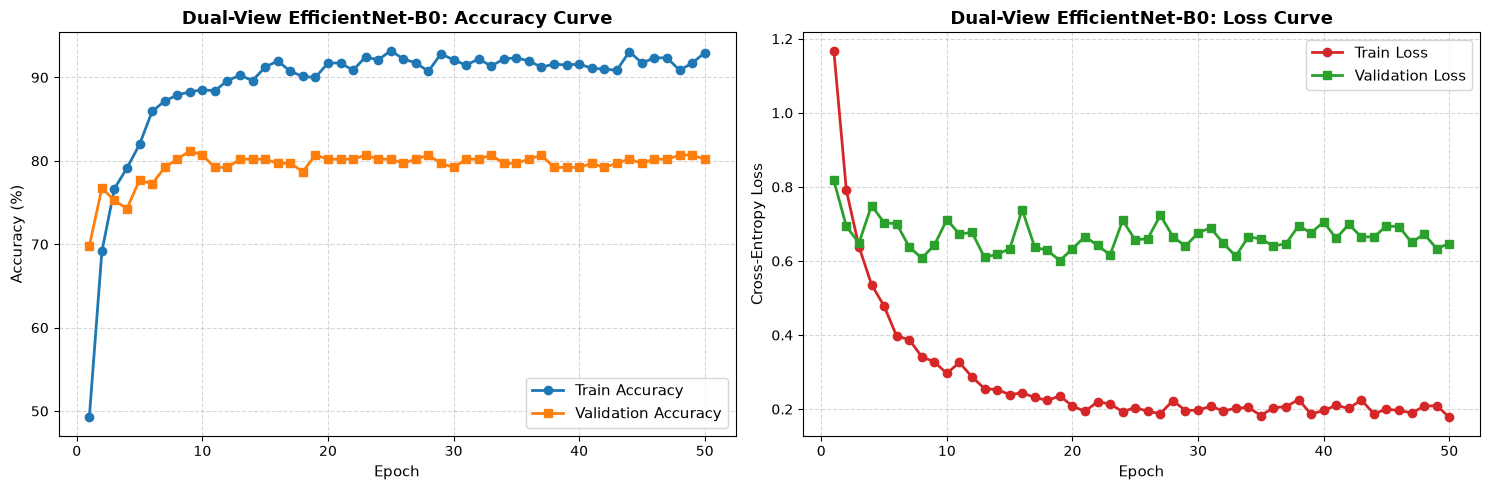

TRAINING GRAPHS SAVED PERMANENTLY
Combined graph : D:\Segregation\Training_Graphs\training_curves.png
Accuracy graph : D:\Segregation\Training_Graphs\accuracy_curve.png
Loss graph     : D:\Segregation\Training_Graphs\loss_curve.png


In [4]:
from pathlib import Path
import matplotlib.pyplot as plt

# =========================================================
# PERMANENT GRAPH SAVE LOCATION
# =========================================================

GRAPH_DIR = Path(r"D:\Segregation\Training_Graphs")
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

epochs_range = range(1, len(train_accs) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# =========================================================
# ACCURACY CURVE
# =========================================================

ax1.plot(
    epochs_range,
    train_accs,
    marker='o',
    label="Train Accuracy",
    color="#1f77b4",
    linewidth=2
)

ax1.plot(
    epochs_range,
    val_accs,
    marker='s',
    label="Validation Accuracy",
    color="#ff7f0e",
    linewidth=2
)

ax1.set_title(
    "Dual-View EfficientNet-B0: Accuracy Curve",
    fontsize=13,
    fontweight="bold"
)

ax1.set_xlabel("Epoch", fontsize=11)
ax1.set_ylabel("Accuracy (%)", fontsize=11)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(fontsize=11)

# =========================================================
# LOSS CURVE
# =========================================================

ax2.plot(
    epochs_range,
    train_losses,
    marker='o',
    label="Train Loss",
    color="#d62728",
    linewidth=2
)

ax2.plot(
    epochs_range,
    val_losses,
    marker='s',
    label="Validation Loss",
    color="#2ca02c",
    linewidth=2
)

ax2.set_title(
    "Dual-View EfficientNet-B0: Loss Curve",
    fontsize=13,
    fontweight="bold"
)

ax2.set_xlabel("Epoch", fontsize=11)
ax2.set_ylabel("Cross-Entropy Loss", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(fontsize=11)

plt.tight_layout()

# =========================================================
# SAVE PERMANENTLY TO D:
# =========================================================

combined_path = GRAPH_DIR / "training_curves.png"
accuracy_path = GRAPH_DIR / "accuracy_curve.png"
loss_path = GRAPH_DIR / "loss_curve.png"

# Save combined graph
fig.savefig(
    combined_path,
    dpi=300,
    bbox_inches="tight"
)

# Save accuracy separately
fig_acc, ax_acc = plt.subplots(figsize=(8, 6))

ax_acc.plot(
    epochs_range,
    train_accs,
    marker='o',
    label="Train Accuracy",
    color="#1f77b4",
    linewidth=2
)

ax_acc.plot(
    epochs_range,
    val_accs,
    marker='s',
    label="Validation Accuracy",
    color="#ff7f0e",
    linewidth=2
)

ax_acc.set_title(
    "Dual-View EfficientNet-B0: Accuracy Curve",
    fontsize=13,
    fontweight="bold"
)

ax_acc.set_xlabel("Epoch")
ax_acc.set_ylabel("Accuracy (%)")
ax_acc.grid(True, linestyle="--", alpha=0.5)
ax_acc.legend()

fig_acc.tight_layout()

fig_acc.savefig(
    accuracy_path,
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig_acc)

# Save loss separately
fig_loss, ax_loss = plt.subplots(figsize=(8, 6))

ax_loss.plot(
    epochs_range,
    train_losses,
    marker='o',
    label="Train Loss",
    color="#d62728",
    linewidth=2
)

ax_loss.plot(
    epochs_range,
    val_losses,
    marker='s',
    label="Validation Loss",
    color="#2ca02c",
    linewidth=2
)

ax_loss.set_title(
    "Dual-View EfficientNet-B0: Loss Curve",
    fontsize=13,
    fontweight="bold"
)

ax_loss.set_xlabel("Epoch")
ax_loss.set_ylabel("Cross-Entropy Loss")
ax_loss.grid(True, linestyle="--", alpha=0.5)
ax_loss.legend()

fig_loss.tight_layout()

fig_loss.savefig(
    loss_path,
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig_loss)

plt.show()

print("=" * 65)
print("TRAINING GRAPHS SAVED PERMANENTLY")
print("=" * 65)
print(f"Combined graph : {combined_path}")
print(f"Accuracy graph : {accuracy_path}")
print(f"Loss graph     : {loss_path}")
print("=" * 65)

## Step 16 — Upload Testing Folder & Evaluate on Unseen Test Dataset
### 🧪 Dedicated Manual Testing Suite
Satisfies the manual testing requirement:
- **Interactive Folder Selection / ZIP Upload**: Provide a path to a folder containing test images, or upload a ZIP archive of test images.
- **Automated Pair Detection**: Automatically identifies corresponding **T1 and B1 image pairs**.
- **Simultaneous Dual-View Inference**: Runs both images through the trained model and performs feature fusion.
- **Full Evaluation Metrics**: Computes **Accuracy**, **Precision**, **Recall**, **F1-Score**, **Confusion Matrix Heatmap**, and exports all individual test predictions to `test_predictions.csv`.

In [33]:
import torch

print("=" * 55)
print("GPU ENVIRONMENT CHECK")
print("=" * 55)

print("PyTorch         :", torch.__version__)
print("CUDA Version    :", torch.version.cuda)
print("CUDA Available  :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU             :", torch.cuda.get_device_name(0))
    print(
        "VRAM            :",
        round(
            torch.cuda.get_device_properties(0).total_memory / (1024**3),
            2
        ),
        "GB"
    )

print("=" * 55)

GPU ENVIRONMENT CHECK
PyTorch         : 2.14.1+cu126
CUDA Version    : 12.6
CUDA Available  : True
GPU             : NVIDIA GeForce RTX 2050
VRAM            : 4.0 GB


In [34]:
import torch
import torch.nn as nn
from torchvision import models

# ============================================================
# DUAL-VIEW EFFICIENTNET-B0 MODEL
# ============================================================

class DualViewEfficientNetB0(nn.Module):

    def __init__(self, num_classes=4):
        super().__init__()

        # ----------------------------------------------------
        # TOP VIEW ENCODER
        # ----------------------------------------------------
        self.top_encoder = models.efficientnet_b0(
            weights=None
        )

        # EfficientNet-B0 feature size = 1280
        top_features = self.top_encoder.classifier[1].in_features

        # Remove original classifier
        self.top_encoder.classifier = nn.Identity()

        # ----------------------------------------------------
        # BOTTOM VIEW ENCODER
        # ----------------------------------------------------
        self.bottom_encoder = models.efficientnet_b0(
            weights=None
        )

        self.bottom_encoder.classifier = nn.Identity()

        # ----------------------------------------------------
        # FUSION
        # ----------------------------------------------------
        # 1280 TOP + 1280 BOTTOM = 2560
        combined_features = top_features * 2

        # ----------------------------------------------------
        # CLASSIFIER
        # ----------------------------------------------------
        self.classifier = nn.Sequential(

            nn.Dropout(0.3),

            nn.Linear(
                combined_features,
                512
            ),

            nn.BatchNorm1d(512),

            nn.SiLU(inplace=True),

            nn.Dropout(0.3),

            nn.Linear(
                512,
                num_classes
            )
        )

    def forward(self, top_image, bottom_image):

        # Extract TOP features
        top_features = self.top_encoder(top_image)

        # Extract BOTTOM features
        bottom_features = self.bottom_encoder(bottom_image)

        # Concatenate both views
        combined = torch.cat(
            [top_features, bottom_features],
            dim=1
        )

        # Classification
        output = self.classifier(combined)

        return output


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("CREATING DUAL-VIEW EFFICIENTNET-B0")
print("=" * 70)

# ============================================================
# CREATE MODEL
# ============================================================

classes = [
    "Brown spot",
    "Healthy Paddy",
    "Hispa",
    "Leaf Blast"
]

NUM_CLASSES = len(classes)

model = DualViewEfficientNetB0(
    num_classes=NUM_CLASSES
)

model = model.to(device)

# ============================================================
# MODEL INFORMATION
# ============================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Number of classes     : {NUM_CLASSES}")
print(f"Classes               : {classes}")
print(f"Total parameters      : {total_params:,}")
print(f"Trainable parameters  : {trainable_params:,}")

print("\nClassifier:")
print(model.classifier)

print("\nDevice:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("=" * 70)
print("✓ MODEL CREATED SUCCESSFULLY")
print("=" * 70)

CREATING DUAL-VIEW EFFICIENTNET-B0
Number of classes     : 4
Classes               : ['Brown spot', 'Healthy Paddy', 'Hispa', 'Leaf Blast']
Total parameters      : 9,329,404
Trainable parameters  : 9,329,404

Classifier:
Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=2560, out_features=512, bias=True)
  (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (3): SiLU(inplace=True)
  (4): Dropout(p=0.3, inplace=False)
  (5): Linear(in_features=512, out_features=4, bias=True)
)

Device: cuda
GPU: NVIDIA GeForce RTX 2050
✓ MODEL CREATED SUCCESSFULLY


        DUAL-VIEW EFFICIENTNET-B0 TESTING
Device : cuda
GPU    : NVIDIA GeForce RTX 2050
VRAM   : 4.00 GB

✓ Evaluation transform ready
  Image size : 224 x 224
  Channels   : RGB
  Normalize  : ImageNet

CREATING EXACT TRAINING ARCHITECTURE
Number of classes     : 4
Classes               : ['Brown spot', 'Healthy Paddy', 'Hispa', 'Leaf Blast']
Total parameters      : 5,321,856
Trainable parameters  : 5,321,856

Classifier:
Sequential(
  (0): Dropout(p=0.3, inplace=True)
  (1): Linear(in_features=2560, out_features=512, bias=True)
  (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (3): SiLU(inplace=True)
  (4): Dropout(p=0.3, inplace=True)
  (5): Linear(in_features=512, out_features=4, bias=True)
)

Device: cuda
GPU: NVIDIA GeForce RTX 2050

LOADING BEST DUAL-VIEW EFFICIENTNET-B0 MODEL
✓ Model file found:
  D:\Segregation\best_dual_efficientnet_b0.pth

Loading checkpoint...

✓ BEST MODEL LOADED SUCCESSFULLY
✓ Model: D:\Segregation\best_

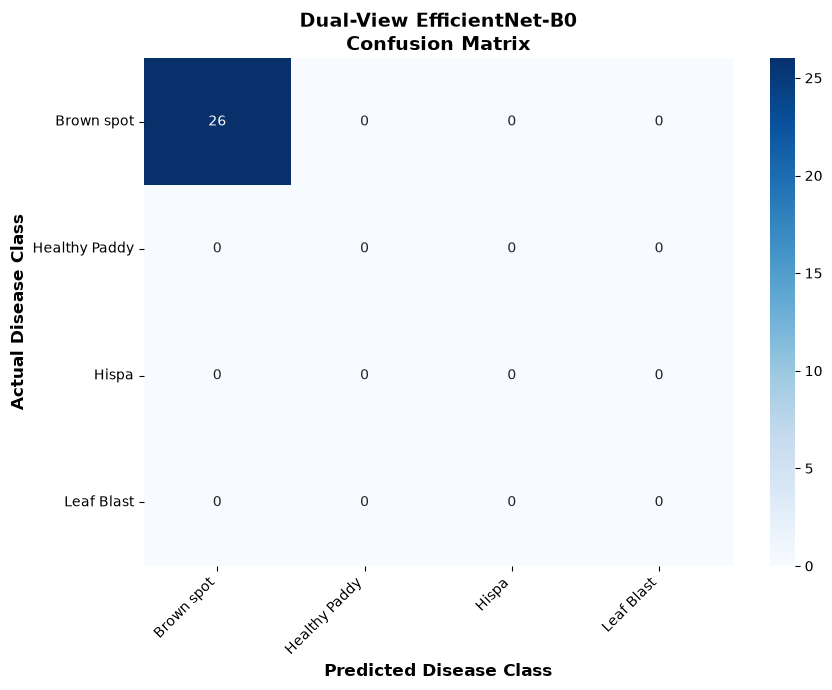


✓ Confusion matrix saved to:
  D:\Segregation final tamma\Brown Spot\Testing_Brown_Spot\dual_view_confusion_matrix.png


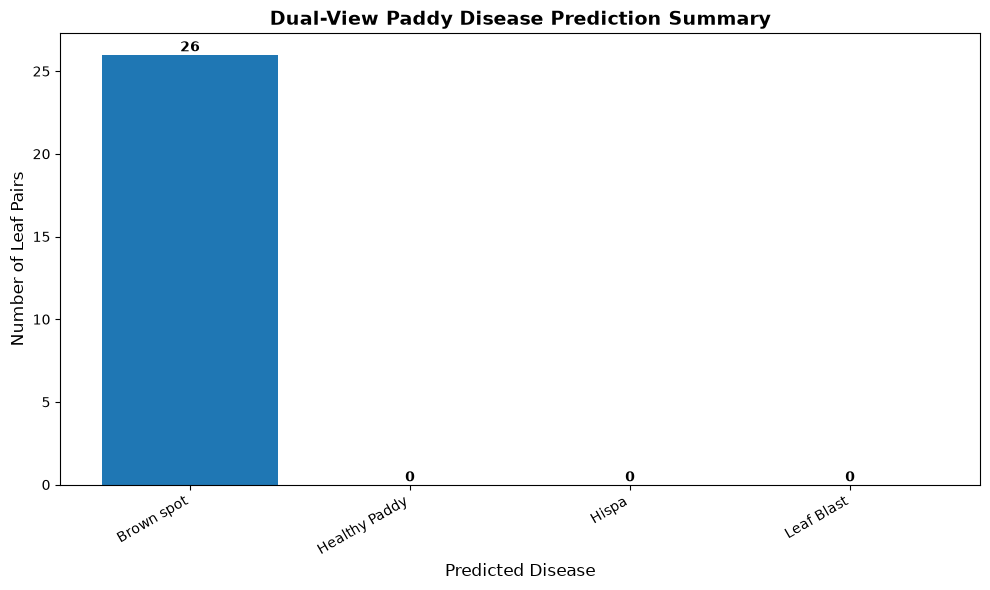


✓ Prediction summary chart saved to:
  D:\Segregation final tamma\Brown Spot\Testing_Brown_Spot\dual_view_prediction_summary.png

                 TESTING COMPLETED
Testing folder       : D:\Segregation final tamma\Brown Spot\Testing_Brown_Spot
Total images         : 54
Complete T+B pairs   : 26
Predictions generated: 26
Results CSV          : D:\Segregation final tamma\Brown Spot\Testing_Brown_Spot\dual_view_test_predictions.csv
Summary chart        : D:\Segregation final tamma\Brown Spot\Testing_Brown_Spot\dual_view_prediction_summary.png

✓ ALL TESTING FINISHED SUCCESSFULLY


In [10]:
# ==============================================================================
# DUAL-VIEW EFFICIENTNET-B0
# COMPLETE TESTING CODE - FIXED
#
# IMPORTANT:
# This code recreates the SAME architecture used during training.
#
# Training architecture:
#   Shared EfficientNet-B0
#   TOP    -> shared backbone -> 1280
#   BOTTOM -> shared backbone -> 1280
#   Fusion -> 2560
#   Classifier:
#       Dropout
#       Linear(2560 -> 512)
#       BatchNorm1d(512)
#       SiLU
#       Dropout
#       Linear(512 -> 4)
#
# Model:
#   D:\Segregation\best_dual_efficientnet_b0.pth
# ==============================================================================


# ==============================================================================
# 1. IMPORTS
# ==============================================================================

import os
import re
import json
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from tkinter import Tk, filedialog

import torch
import torch.nn as nn

from torchvision import transforms
from torchvision.models import efficientnet_b0

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
)


# ==============================================================================
# 2. CONFIGURATION
# ==============================================================================

BEST_MODEL_PATH = r"D:\Segregation\best_dual_efficientnet_b0.pth"

CLASSES = [
    "Brown spot",
    "Healthy Paddy",
    "Hispa",
    "Leaf Blast"
]

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
}

IMG_SIZE = 224

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


# ==============================================================================
# 3. DEVICE
# ==============================================================================

print("=" * 75)
print("        DUAL-VIEW EFFICIENTNET-B0 TESTING")
print("=" * 75)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Device : {device}")

if torch.cuda.is_available():

    print(
        f"GPU    : "
        f"{torch.cuda.get_device_name(0)}"
    )

    print(
        f"VRAM   : "
        f"{torch.cuda.get_device_properties(0).total_memory / (1024 ** 3):.2f} GB"
    )

print("=" * 75)


# ==============================================================================
# 4. EVALUATION TRANSFORM
# ==============================================================================

eval_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )

])

print()
print("✓ Evaluation transform ready")
print(f"  Image size : {IMG_SIZE} x {IMG_SIZE}")
print("  Channels   : RGB")
print("  Normalize  : ImageNet")

print("=" * 75)


# ==============================================================================
# 5. EXACT MODEL ARCHITECTURE USED DURING TRAINING
# ==============================================================================

class DualViewEfficientNetB0(nn.Module):

    """
    SAME architecture used during training.

    TOP image
        |
        v
    Shared EfficientNet-B0
        |
      1280

    BOTTOM image
        |
        v
    SAME Shared EfficientNet-B0
        |
      1280

    Concatenate:
        1280 + 1280 = 2560

    Classifier:
        Dropout
        Linear(2560 -> 512)
        BatchNorm1d
        SiLU
        Dropout
        Linear(512 -> 4)
    """

    def __init__(
        self,
        num_classes=4,
        pretrained=False,
        dropout_rate=0.3
    ):

        super().__init__()

        # ----------------------------------------------------------------------
        # EfficientNet-B0
        #
        # IMPORTANT:
        # weights=None is used because the trained .pth file already contains
        # the trained backbone weights.
        # ----------------------------------------------------------------------

        base_model = efficientnet_b0(
            weights=None
        )

        # ----------------------------------------------------------------------
        # SAME SHARED FEATURE EXTRACTOR AS TRAINING
        # ----------------------------------------------------------------------

        self.features = base_model.features

        self.avgpool = base_model.avgpool

        backbone_features = (
            base_model.classifier[1].in_features
        )

        # Expected:
        # backbone_features = 1280

        # ----------------------------------------------------------------------
        # SAME CLASSIFIER AS TRAINING
        # ----------------------------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Dropout(
                p=dropout_rate,
                inplace=True
            ),

            nn.Linear(
                backbone_features * 2,
                512
            ),

            nn.BatchNorm1d(
                512
            ),

            nn.SiLU(
                inplace=True
            ),

            nn.Dropout(
                p=dropout_rate,
                inplace=True
            ),

            nn.Linear(
                512,
                num_classes
            )
        )


    # ==========================================================================
    # FEATURE EXTRACTION
    # ==========================================================================

    def extract_features(self, x):

        x = self.features(x)

        x = self.avgpool(x)

        x = torch.flatten(
            x,
            1
        )

        return x


    # ==========================================================================
    # FORWARD
    # ==========================================================================

    def forward(
        self,
        img_top,
        img_bottom=None
    ):

        # Safety fallback
        if img_bottom is None:
            img_bottom = img_top

        # TOP
        feat_top = self.extract_features(
            img_top
        )

        # BOTTOM
        feat_bottom = self.extract_features(
            img_bottom
        )

        # ----------------------------------------------------------------------
        # FEATURE FUSION
        # ----------------------------------------------------------------------

        fused = torch.cat(
            [
                feat_top,
                feat_bottom
            ],
            dim=1
        )

        # ----------------------------------------------------------------------
        # CLASSIFIER
        # ----------------------------------------------------------------------

        logits = self.classifier(
            fused
        )

        return logits


# ==============================================================================
# 6. CREATE MODEL
# ==============================================================================

print()
print("=" * 75)
print("CREATING EXACT TRAINING ARCHITECTURE")
print("=" * 75)

model = DualViewEfficientNetB0(
    num_classes=4,
    pretrained=False,
    dropout_rate=0.3
)

model = model.to(device)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    f"Number of classes     : {len(CLASSES)}"
)

print(
    f"Classes               : {CLASSES}"
)

print(
    f"Total parameters      : {total_params:,}"
)

print(
    f"Trainable parameters  : {trainable_params:,}"
)

print()
print("Classifier:")
print(model.classifier)

print()
print(f"Device: {device}")

if torch.cuda.is_available():

    print(
        f"GPU: "
        f"{torch.cuda.get_device_name(0)}"
    )

print("=" * 75)


# ==============================================================================
# 7. CHECK MODEL FILE
# ==============================================================================

print()
print("=" * 75)
print("LOADING BEST DUAL-VIEW EFFICIENTNET-B0 MODEL")
print("=" * 75)

if not os.path.exists(
    BEST_MODEL_PATH
):

    raise FileNotFoundError(
        "\n❌ MODEL FILE NOT FOUND\n\n"
        f"Expected:\n"
        f"{BEST_MODEL_PATH}\n"
    )

print(
    "✓ Model file found:"
)

print(
    f"  {BEST_MODEL_PATH}"
)


# ==============================================================================
# 8. LOAD CHECKPOINT
# ==============================================================================

print()
print("Loading checkpoint...")

try:

    checkpoint = torch.load(
        BEST_MODEL_PATH,
        map_location=device
    )

    # --------------------------------------------------------------------------
    # Handle different checkpoint formats
    # --------------------------------------------------------------------------

    if isinstance(
        checkpoint,
        dict
    ):

        if "state_dict" in checkpoint:

            state_dict = checkpoint[
                "state_dict"
            ]

        elif "model_state_dict" in checkpoint:

            state_dict = checkpoint[
                "model_state_dict"
            ]

        else:

            state_dict = checkpoint

    else:

        raise RuntimeError(
            "Checkpoint is not a valid state_dict."
        )


    # --------------------------------------------------------------------------
    # Remove DataParallel prefix if present
    # --------------------------------------------------------------------------

    cleaned_state_dict = {}

    for key, value in state_dict.items():

        if key.startswith(
            "module."
        ):

            key = key[
                len("module.") :
            ]

        cleaned_state_dict[
            key
        ] = value


    # --------------------------------------------------------------------------
    # STRICT LOAD
    # --------------------------------------------------------------------------

    model.load_state_dict(
        cleaned_state_dict,
        strict=True
    )


except RuntimeError as e:

    print()
    print("!" * 75)
    print("❌ CHECKPOINT / ARCHITECTURE ERROR")
    print("!" * 75)

    print()
    print(
        "The checkpoint cannot be loaded into the architecture."
    )

    print()
    print(
        "This code uses the architecture from your training notebook:"
    )

    print(
        "  Shared EfficientNet-B0"
    )

    print(
        "  TOP    -> 1280"
    )

    print(
        "  BOTTOM -> 1280"
    )

    print(
        "  Fusion -> 2560"
    )

    print(
        "  Head   -> 512 -> 4"
    )

    print()
    print(
        "Original PyTorch error:"
    )

    print(e)

    print("!" * 75)

    raise


# ==============================================================================
# 9. MODEL READY
# ==============================================================================

model = model.to(
    device
)

model.eval()

print()
print(
    "✓ BEST MODEL LOADED SUCCESSFULLY"
)

print(
    f"✓ Model:"
    f" {BEST_MODEL_PATH}"
)

print(
    f"✓ Device:"
    f" {device}"
)

if torch.cuda.is_available():

    print(
        f"✓ GPU:"
        f" {torch.cuda.get_device_name(0)}"
    )

print("=" * 75)


# ==============================================================================
# 10. MODEL CLASSES
# ==============================================================================

print()
print("MODEL CLASSES")

for idx, cls in enumerate(
    CLASSES
):

    print(
        f"  {idx}: {cls}"
    )

print("=" * 75)


# ==============================================================================
# 11. SELECT TESTING FOLDER
# ==============================================================================

print()
print("=" * 75)
print("              MANUAL TESTING DATASET")
print("=" * 75)

print(
    """
Select your TESTING DATASET folder.

Supported structure:

OPTION 1
--------

D:\\Testing
    ├── 000001_b1.JPG
    ├── 000002_t1.JPG
    ├── 000003_b2.JPG
    ├── 000004_t2.JPG
    └── ...


OPTION 2
--------

D:\\Testing
    ├── Brown spot
    │     ├── 000001_b1.JPG
    │     ├── 000002_t1.JPG
    │     └── ...
    │
    ├── Healthy Paddy
    │
    ├── Hispa
    │
    └── Leaf Blast


PAIRING:

000206_t698.JPG
        +
000205_b698.JPG

        ↓

PAIR NUMBER = 698


The number after _t / _b is used for pairing.

The number at the beginning of the filename
is NOT used for pairing.
"""
)


# ==============================================================================
# 12. WINDOWS FOLDER SELECTOR
# ==============================================================================

root = Tk()

root.withdraw()

root.attributes(
    "-topmost",
    True
)

TEST_DIR = filedialog.askdirectory(
    title="Select Testing Dataset Folder"
)

root.destroy()


# ==============================================================================
# 13. CHECK FOLDER
# ==============================================================================

if not TEST_DIR:

    raise RuntimeError(
        "\n❌ No testing folder selected."
    )

TEST_DIR = str(
    Path(TEST_DIR)
)

test_path = Path(
    TEST_DIR
)

print()
print(
    "✓ Testing folder selected:"
)

print(
    f"  {TEST_DIR}"
)


# ==============================================================================
# 14. FIND ALL IMAGES
# ==============================================================================

all_test_files = [

    f

    for f in test_path.rglob("*")

    if (
        f.is_file()
        and
        f.suffix.lower()
        in IMAGE_EXTENSIONS
    )

]


print()
print("=" * 75)
print("TEST DATASET DISCOVERY")
print("=" * 75)

print(
    f"Total images discovered : "
    f"{len(all_test_files)}"
)


if len(all_test_files) == 0:

    raise RuntimeError(
        "\n❌ No image files found."
    )


# ==============================================================================
# 15. NORMALIZE CLASS NAMES
# ==============================================================================

def normalize_class_name(
    name
):

    return (
        name
        .lower()
        .replace(
            " ",
            ""
        )
        .replace(
            "_",
            ""
        )
        .replace(
            "-",
            ""
        )
    )


normalized_classes = {

    normalize_class_name(cls):
    cls

    for cls in CLASSES

}


# ==============================================================================
# 16. DETECT TRUE CLASS
# ==============================================================================

def get_true_class(
    file_path
):

    for parent in file_path.parents:

        normalized = normalize_class_name(
            parent.name
        )

        if normalized in normalized_classes:

            return normalized_classes[
                normalized
            ]

    return None


# ==============================================================================
# 17. EXTRACT PAIR NUMBER
# ==============================================================================

def extract_pair_number(
    file_path
):

    name = file_path.stem.lower()

    # --------------------------------------------------------------------------
    # Normal format
    #
    # 000206_t698
    # 000205_b698
    # --------------------------------------------------------------------------

    match = re.search(
        r"[_-](?:t|b)(\d+)$",
        name
    )

    if match:

        return int(
            match.group(1)
        )


    # --------------------------------------------------------------------------
    # Fallback
    #
    # t698
    # b698
    # --------------------------------------------------------------------------

    match = re.search(
        r"(?:t|b)(\d+)$",
        name
    )

    if match:

        return int(
            match.group(1)
        )


    return None


# ==============================================================================
# 18. DETECT TOP IMAGE
# ==============================================================================

def is_top_image(
    file_path
):

    name = file_path.stem.lower()

    return bool(
        re.search(
            r"[_-]t\d+$",
            name
        )
    )


# ==============================================================================
# 19. DETECT BOTTOM IMAGE
# ==============================================================================

def is_bottom_image(
    file_path
):

    name = file_path.stem.lower()

    return bool(
        re.search(
            r"[_-]b\d+$",
            name
        )
    )


# ==============================================================================
# 20. GROUP IMAGES
# ==============================================================================

test_groups = defaultdict(

    lambda: {

        "top": [],
        "bottom": [],
        "true_class": None,
        "pair_number": None

    }

)


for file_path in all_test_files:

    pair_number = extract_pair_number(
        file_path
    )

    true_class = get_true_class(
        file_path
    )


    if pair_number is None:

        print(
            f"⚠ Could not determine pair number: "
            f"{file_path.name}"
        )

        continue


    group_key = (
        true_class,
        pair_number
    )


    test_groups[
        group_key
    ][
        "true_class"
    ] = true_class


    test_groups[
        group_key
    ][
        "pair_number"
    ] = pair_number


    if is_top_image(
        file_path
    ):

        test_groups[
            group_key
        ][
            "top"
        ].append(
            file_path
        )


    elif is_bottom_image(
        file_path
    ):

        test_groups[
            group_key
        ][
            "bottom"
        ].append(
            file_path
        )


# ==============================================================================
# 21. CREATE COMPLETE T+B PAIRS
# ==============================================================================

test_pairs = []

missing_top = 0
missing_bottom = 0


for group_key, data in sorted(

    test_groups.items(),

    key=lambda x: (
        str(x[0][0]),
        x[0][1]
    )

):

    true_class = data[
        "true_class"
    ]

    pair_number = data[
        "pair_number"
    ]

    top_files = data[
        "top"
    ]

    bottom_files = data[
        "bottom"
    ]


    # --------------------------------------------------------------------------
    # Missing TOP
    # --------------------------------------------------------------------------

    if not top_files:

        print(
            f"⚠ Missing TOP image: "
            f"{true_class} #{pair_number}"
        )

        missing_top += 1

        continue


    # --------------------------------------------------------------------------
    # Missing BOTTOM
    # --------------------------------------------------------------------------

    if not bottom_files:

        print(
            f"⚠ Missing BOTTOM image: "
            f"{true_class} #{pair_number}"
        )

        missing_bottom += 1

        continue


    # --------------------------------------------------------------------------
    # Select T and B
    # --------------------------------------------------------------------------

    top_file = sorted(
        top_files
    )[0]

    bottom_file = sorted(
        bottom_files
    )[0]


    test_pairs.append({

        "leaf_id":
            pair_number,

        "top_path":
            top_file,

        "bottom_path":
            bottom_file,

        "true_class":
            true_class

    })


# ==============================================================================
# 22. PAIRING VERIFICATION
# ==============================================================================

print()
print("=" * 75)
print("PAIRING VERIFICATION")
print("=" * 75)

print(
    f"Complete T+B pairs : "
    f"{len(test_pairs)}"
)

print(
    f"Missing TOP        : "
    f"{missing_top}"
)

print(
    f"Missing BOTTOM     : "
    f"{missing_bottom}"
)

print()
print("First 10 pairs:")
print()


for i, item in enumerate(

    test_pairs[:10],

    start=1

):

    print(

        f"{i:02d}. "
        f"TOP = "
        f"{item['top_path'].name:<30} | "
        f"BOTTOM = "
        f"{item['bottom_path'].name:<30} | "
        f"PAIR = "
        f"{item['leaf_id']:<5} | "
        f"CLASS = "
        f"{item['true_class']}"

    )


print("=" * 75)


if len(test_pairs) == 0:

    raise RuntimeError(
        "\n❌ No complete T+B pairs found."
    )


# ==============================================================================
# 23. RUN DUAL-VIEW TESTING
# ==============================================================================

print()
print("=" * 75)
print("RUNNING DUAL-VIEW TESTING")
print("=" * 75)


predictions = []


model.eval()


with torch.inference_mode():

    for count, item in enumerate(

        test_pairs,

        start=1

    ):

        # ----------------------------------------------------------------------
        # Load TOP
        # ----------------------------------------------------------------------

        img_top = Image.open(
            item["top_path"]
        ).convert(
            "RGB"
        )


        # ----------------------------------------------------------------------
        # Load BOTTOM
        # ----------------------------------------------------------------------

        img_bottom = Image.open(
            item["bottom_path"]
        ).convert(
            "RGB"
        )


        # ----------------------------------------------------------------------
        # Transform TOP
        # ----------------------------------------------------------------------

        tensor_top = (

            eval_transform(
                img_top
            )

            .unsqueeze(0)

            .to(
                device,
                non_blocking=True
            )

        )


        # ----------------------------------------------------------------------
        # Transform BOTTOM
        # ----------------------------------------------------------------------

        tensor_bottom = (

            eval_transform(
                img_bottom
            )

            .unsqueeze(0)

            .to(
                device,
                non_blocking=True
            )

        )


        # ----------------------------------------------------------------------
        # BOTH IMAGES ENTER THE SAME MODEL
        # ----------------------------------------------------------------------

        outputs = model(

            tensor_top,
            tensor_bottom

        )


        # ----------------------------------------------------------------------
        # SOFTMAX
        # ----------------------------------------------------------------------

        probs = torch.softmax(

            outputs,

            dim=1

        )[0].cpu().numpy()


        # ----------------------------------------------------------------------
        # HIGHEST PROBABILITY
        # ----------------------------------------------------------------------

        pred_idx = int(
            np.argmax(
                probs
            )
        )


        confidence = float(
            probs[pred_idx]
        )


        pred_class = CLASSES[
            pred_idx
        ]


        # ----------------------------------------------------------------------
        # SAVE RESULT
        # ----------------------------------------------------------------------

        record = {

            "Leaf_ID":
                item["leaf_id"],

            "Top_Image":
                item["top_path"].name,

            "Bottom_Image":
                item["bottom_path"].name,

            "Predicted_Class":
                pred_class,

            "Confidence":
                confidence * 100,

            "True_Class":
                item["true_class"]

        }


        # ----------------------------------------------------------------------
        # SAVE ALL CLASS PROBABILITIES
        # ----------------------------------------------------------------------

        for c_idx, c_name in enumerate(
            CLASSES
        ):

            record[
                f"Prob_{c_name}"
            ] = (
                probs[c_idx] * 100
            )


        predictions.append(
            record
        )


        # ----------------------------------------------------------------------
        # DISPLAY RESULT
        # ----------------------------------------------------------------------

        print(

            f"{count:04d}/"
            f"{len(test_pairs):04d} | "

            f"T1: "
            f"{item['top_path'].name:<25} | "

            f"B1: "
            f"{item['bottom_path'].name:<25} | "

            f"Prediction: "
            f"{pred_class:<15} | "

            f"Confidence: "
            f"{confidence * 100:.2f}%"

        )


# ==============================================================================
# 24. CREATE DATAFRAME
# ==============================================================================

df_test_results = pd.DataFrame(
    predictions
)


# ==============================================================================
# 25. SAVE DETAILED RESULTS PERMANENTLY
# ==============================================================================

results_csv = (

    test_path /
    "dual_view_test_predictions.csv"

)


df_test_results.to_csv(

    results_csv,

    index=False

)


print()
print(
    "✓ Detailed predictions saved to:"
)

print(
    f"  {results_csv}"
)


# ==============================================================================
# 26. PREDICTION COUNTS
# ==============================================================================

prediction_counts = (

    df_test_results[
        "Predicted_Class"
    ]

    .value_counts()

)


print()
print("=" * 75)
print("PREDICTED CLASS COUNTS")
print("=" * 75)


for cls in CLASSES:

    count = int(

        prediction_counts.get(
            cls,
            0
        )

    )

    print(
        f"{cls:<22}: {count}"
    )


print("=" * 75)


# ==============================================================================
# 27. PREDICTION COUNT
# ==============================================================================

print()

print(
    f"Prediction Count       : "
    f"{len(df_test_results)}/"
    f"{len(test_pairs)}"
)


# ==============================================================================
# 28. FINAL OVERALL PREDICTION
# ==============================================================================

if len(
    df_test_results
) > 0:

    final_disease = (

        prediction_counts
        .idxmax()

    )


    final_count = int(

        prediction_counts
        .max()

    )


    final_percentage = (

        final_count /
        len(df_test_results)

    ) * 100


    print()
    print("=" * 75)
    print("                  FINAL DIAGNOSIS")
    print("=" * 75)


    print(
        f"Final Predicted Disease : "
        f"{final_disease}"
    )


    print(
        f"Prediction Count        : "
        f"{final_count}/"
        f"{len(df_test_results)}"
    )


    print(
        f"Prediction Percentage   : "
        f"{final_percentage:.2f}%"
    )


    print("=" * 75)


# ==============================================================================
# 29. EVALUATION IF TEST FOLDER HAS CLASS FOLDERS
# ==============================================================================

labeled_test = df_test_results[

    df_test_results[
        "True_Class"
    ].notnull()

]


if len(
    labeled_test
) > 0:

    y_true = labeled_test[
        "True_Class"
    ].tolist()


    y_pred = labeled_test[
        "Predicted_Class"
    ].tolist()


    # --------------------------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------------------------

    acc = accuracy_score(

        y_true,
        y_pred

    )


    # --------------------------------------------------------------------------
    # Macro metrics
    # --------------------------------------------------------------------------

    (
        macro_p,
        macro_r,
        macro_f1,
        _
    ) = precision_recall_fscore_support(

        y_true,
        y_pred,

        labels=CLASSES,

        average="macro",

        zero_division=0

    )


    # --------------------------------------------------------------------------
    # Weighted metrics
    # --------------------------------------------------------------------------

    (
        weighted_p,
        weighted_r,
        weighted_f1,
        _
    ) = precision_recall_fscore_support(

        y_true,
        y_pred,

        labels=CLASSES,

        average="weighted",

        zero_division=0

    )


    # --------------------------------------------------------------------------
    # FINAL METRICS
    # --------------------------------------------------------------------------

    print()
    print("=" * 75)
    print("FINAL TEST EVALUATION METRICS")
    print("=" * 75)


    print(
        f"Total Test Leaf Pairs : "
        f"{len(labeled_test)}"
    )


    print(
        f"Overall Accuracy      : "
        f"{acc * 100:.2f}%"
    )


    print(
        f"Macro Precision       : "
        f"{macro_p * 100:.2f}%"
    )


    print(
        f"Macro Recall          : "
        f"{macro_r * 100:.2f}%"
    )


    print(
        f"Macro F1-Score        : "
        f"{macro_f1 * 100:.2f}%"
    )


    print(
        f"Weighted F1-Score     : "
        f"{weighted_f1 * 100:.2f}%"
    )


    print("=" * 75)


    # ==============================================================================
    # 30. CLASSIFICATION REPORT
    # ==============================================================================

    print()
    print("CLASSIFICATION REPORT")
    print("=" * 75)


    print(

        classification_report(

            y_true,
            y_pred,

            labels=CLASSES,

            target_names=CLASSES,

            digits=4,

            zero_division=0

        )

    )


    # ==============================================================================
    # 31. CONFUSION MATRIX
    # ==============================================================================

    cm = confusion_matrix(

        y_true,
        y_pred,

        labels=CLASSES

    )


    plt.figure(
        figsize=(9, 7)
    )


    sns.heatmap(

        cm,

        annot=True,

        fmt="d",

        cmap="Blues",

        xticklabels=CLASSES,

        yticklabels=CLASSES

    )


    plt.xlabel(
        "Predicted Disease Class",
        fontsize=12,
        fontweight="bold"
    )


    plt.ylabel(
        "Actual Disease Class",
        fontsize=12,
        fontweight="bold"
    )


    plt.title(

        "Dual-View EfficientNet-B0\n"
        "Confusion Matrix",

        fontsize=14,

        fontweight="bold"

    )


    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.yticks(
        rotation=0
    )


    plt.tight_layout()


    confusion_path = (

        test_path /
        "dual_view_confusion_matrix.png"

    )


    plt.savefig(

        confusion_path,

        dpi=300,

        bbox_inches="tight"

    )


    plt.show()


    print()
    print(
        "✓ Confusion matrix saved to:"
    )

    print(
        f"  {confusion_path}"
    )


else:

    print()
    print("=" * 75)
    print("UNLABELED TEST DATA")
    print("=" * 75)

    print(
        "No recognized disease-class folder was found."
    )

    print(
        "Predictions were generated successfully."
    )

    print(
        "Accuracy cannot be calculated because true labels are unavailable."
    )


# ==============================================================================
# 32. SUMMARY BAR CHART
# ==============================================================================

plt.figure(
    figsize=(10, 6)
)


counts = [

    int(
        prediction_counts.get(
            cls,
            0
        )
    )

    for cls in CLASSES

]


bars = plt.bar(

    CLASSES,

    counts

)


plt.xlabel(
    "Predicted Disease",
    fontsize=12
)

plt.ylabel(
    "Number of Leaf Pairs",
    fontsize=12
)


plt.title(

    "Dual-View Paddy Disease Prediction Summary",

    fontsize=14,

    fontweight="bold"

)


plt.xticks(
    rotation=30,
    ha="right"
)


for bar, count in zip(
    bars,
    counts
):

    plt.text(

        bar.get_x()
        + bar.get_width() / 2,

        bar.get_height(),

        str(count),

        ha="center",

        va="bottom",

        fontweight="bold"

    )


plt.tight_layout()


summary_chart_path = (

    test_path /
    "dual_view_prediction_summary.png"

)


plt.savefig(

    summary_chart_path,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


print()
print(
    "✓ Prediction summary chart saved to:"
)

print(
    f"  {summary_chart_path}"
)


# ==============================================================================
# 33. FINAL SUMMARY
# ==============================================================================

print()
print("=" * 75)
print("                 TESTING COMPLETED")
print("=" * 75)

print(
    f"Testing folder       : "
    f"{TEST_DIR}"
)

print(
    f"Total images         : "
    f"{len(all_test_files)}"
)

print(
    f"Complete T+B pairs   : "
    f"{len(test_pairs)}"
)

print(
    f"Predictions generated: "
    f"{len(df_test_results)}"
)

print(
    f"Results CSV          : "
    f"{results_csv}"
)

print(
    f"Summary chart        : "
    f"{summary_chart_path}"
)

print("=" * 75)

print()
print("✓ ALL TESTING FINISHED SUCCESSFULLY")

## Step 17 — Single-Leaf Interactive Diagnosis (Upload T1 & B1)
Interactive demonstration to upload the front and back photos of any paddy leaf and view real-time dual-view diagnostic results.

        DUAL-VIEW PADDY LEAF DIAGNOSIS
Total T1+B1 pairs : 26
Device            : cuda
GPU               : NVIDIA GeForce RTX 2050
0001/0026 | T1: 000242_t466.JPG           | B1: 000241_b466.JPG           | Prediction: Leaf Blast      | Confidence: 87.45%
0002/0026 | T1: 000264_t488.JPG           | B1: 000263_b488.JPG           | Prediction: Leaf Blast      | Confidence: 52.76%
0003/0026 | T1: 000206_t698.JPG           | B1: 000205_b698.JPG           | Prediction: Leaf Blast      | Confidence: 97.91%
0004/0026 | T1: 000208_t700.JPG           | B1: 000207_b700.JPG           | Prediction: Leaf Blast      | Confidence: 98.00%
0005/0026 | T1: 000210_t702.JPG           | B1: 000209_b702.JPG           | Prediction: Leaf Blast      | Confidence: 99.16%
0006/0026 | T1: 000212_t704.JPG           | B1: 000211_b704.JPG           | Prediction: Leaf Blast      | Confidence: 87.01%
0007/0026 | T1: 000214_t706.JPG           | B1: 000213_b706.JPG           | Prediction: Leaf Blast      | Confidence: 9

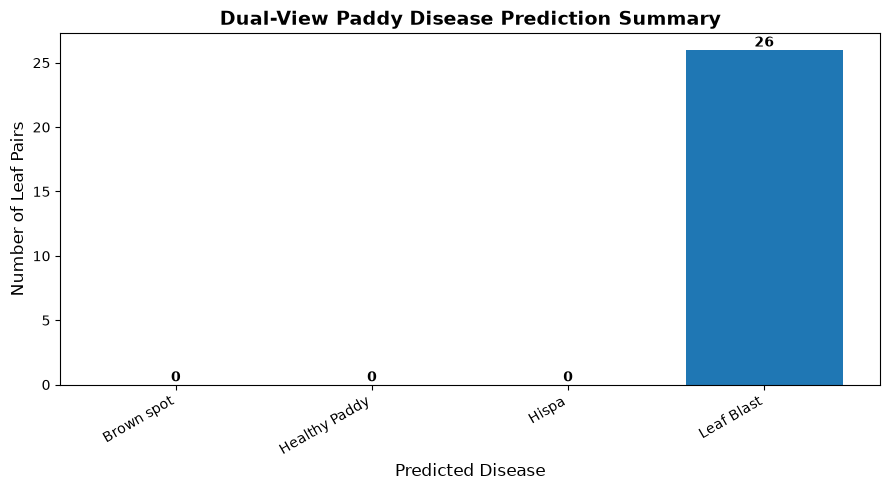

In [61]:
from PIL import Image
import matplotlib.pyplot as plt
import torch
import numpy as np
from pathlib import Path
from collections import Counter
import pandas as pd


# ==============================================================================
# DUAL-VIEW DIAGNOSIS FOR ALL TEST PAIRS
# ==============================================================================

def diagnose_all_leaf_pairs(test_pairs):
    """
    Takes ALL T1 + B1 pairs from test_pairs.

    Each pair is processed simultaneously through the
    Dual-View EfficientNet-B0 model.

    Produces:
      1. Prediction for every leaf pair
      2. Confidence for every prediction
      3. Prediction count for each disease
      4. Final overall predicted disease based on highest count
      5. Detailed CSV results
    """

    model.eval()

    results = []

    print("=" * 75)
    print("        DUAL-VIEW PADDY LEAF DIAGNOSIS")
    print("=" * 75)

    print(f"Total T1+B1 pairs : {len(test_pairs)}")
    print(f"Device            : {device}")

    if torch.cuda.is_available():
        print(f"GPU               : {torch.cuda.get_device_name(0)}")

    print("=" * 75)

    # ==========================================================================
    # PROCESS ALL PAIRS
    # ==========================================================================

    with torch.no_grad():

        for count, pair in enumerate(test_pairs, start=1):

            top_path = pair["top_path"]
            bottom_path = pair["bottom_path"]

            # ------------------------------------------------------------------
            # Load T1 / Top image
            # ------------------------------------------------------------------

            img_top = Image.open(top_path).convert("RGB")

            # ------------------------------------------------------------------
            # Load B1 / Bottom image
            # ------------------------------------------------------------------

            img_bottom = Image.open(bottom_path).convert("RGB")

            # ------------------------------------------------------------------
            # Transform
            # ------------------------------------------------------------------

            tensor_top = (
                eval_transform(img_top)
                .unsqueeze(0)
                .to(device)
            )

            tensor_bottom = (
                eval_transform(img_bottom)
                .unsqueeze(0)
                .to(device)
            )

            # ------------------------------------------------------------------
            # Dual-view prediction
            # ------------------------------------------------------------------

            outputs = model(
                tensor_top,
                tensor_bottom
            )

            probs = torch.softmax(
                outputs,
                dim=1
            )[0].cpu().numpy()

            # ------------------------------------------------------------------
            # Highest probability class
            # ------------------------------------------------------------------

            pred_idx = int(np.argmax(probs))

            pred_disease = classes[pred_idx]

            confidence = float(
                probs[pred_idx] * 100
            )

            # ------------------------------------------------------------------
            # Store result
            # ------------------------------------------------------------------

            result = {
                "Pair_Number": pair["leaf_id"],
                "Top_Image": Path(top_path).name,
                "Bottom_Image": Path(bottom_path).name,
                "Predicted_Disease": pred_disease,
                "Confidence": confidence
            }

            # Store probability of every class

            for i, class_name in enumerate(classes):

                result[
                    f"Probability_{class_name}"
                ] = float(probs[i] * 100)

            results.append(result)

            # ------------------------------------------------------------------
            # Display progress
            # ------------------------------------------------------------------

            print(
                f"{count:04d}/{len(test_pairs):04d} | "
                f"T1: {Path(top_path).name:<25} | "
                f"B1: {Path(bottom_path).name:<25} | "
                f"Prediction: {pred_disease:<15} | "
                f"Confidence: {confidence:.2f}%"
            )

    # ==========================================================================
    # CREATE DATAFRAME
    # ==========================================================================

    df_results = pd.DataFrame(results)

    # ==========================================================================
    # PREDICTION COUNTS
    # ==========================================================================

    prediction_counts = Counter(
        df_results["Predicted_Disease"]
    )

    print("\n")
    print("=" * 75)
    print("                    PREDICTION SUMMARY")
    print("=" * 75)

    print(
        f"Total Leaf Pairs     : "
        f"{len(df_results)}"
    )

    print("\nPredicted Classes:")

    for cls in classes:

        count = prediction_counts.get(
            cls,
            0
        )

        print(
            f"  {cls:<20}: {count}"
        )

    # ==========================================================================
    # FIND MOST FREQUENT PREDICTION
    # ==========================================================================

    final_disease = prediction_counts.most_common(1)[0][0]

    final_count = prediction_counts.most_common(1)[0][1]

    final_percentage = (
        final_count /
        len(df_results)
    ) * 100

    print("\n")
    print("=" * 75)
    print("                  FINAL DIAGNOSIS")
    print("=" * 75)

    print(
        f"Final Predicted Disease : "
        f"{final_disease}"
    )

    print(
        f"Prediction Count        : "
        f"{final_count}/{len(df_results)}"
    )

    print(
        f"Prediction Percentage   : "
        f"{final_percentage:.2f}%"
    )

    print("=" * 75)

    # ==========================================================================
    # SAVE CSV
    # ==========================================================================

    results_csv = Path(
        test_pairs[0]["top_path"]
    ).parent.parent / "all_dual_view_predictions.csv"

    df_results.to_csv(
        results_csv,
        index=False
    )

    print(
        f"\n✓ Detailed results saved to:"
    )

    print(
        f"  {results_csv}"
    )

    # ==========================================================================
    # SHOW SUMMARY BAR CHART
    # ==========================================================================

    plt.figure(
        figsize=(9, 5)
    )

    counts = [
        prediction_counts.get(cls, 0)
        for cls in classes
    ]

    bars = plt.bar(
        classes,
        counts
    )

    plt.xlabel(
        "Predicted Disease",
        fontsize=12
    )

    plt.ylabel(
        "Number of Leaf Pairs",
        fontsize=12
    )

    plt.title(
        "Dual-View Paddy Disease Prediction Summary",
        fontsize=14,
        fontweight="bold"
    )

    plt.xticks(
        rotation=30,
        ha="right"
    )

    # Add count above bars

    for bar, count in zip(
        bars,
        counts
    ):

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            str(count),
            ha="center",
            va="bottom",
            fontweight="bold"
        )

    plt.tight_layout()
    plt.show()

    return df_results


# ==============================================================================
# RUN DIAGNOSIS ON ALL T1 + B1 PAIRS
# ==============================================================================

df_all_predictions = diagnose_all_leaf_pairs(
    test_pairs
)

## Step 18 — Save Final Model & Download Artifacts
Saves the final trained model weights and triggers direct download of the key project artifacts:
- `Dual_EfficientNet_B0_Paddy_Disease.pth`
- `class_to_idx.json`
- `accuracy_curve.png`
- `loss_curve.png`
- `test_confusion_matrix.png`
- `test_predictions.csv`

In [ ]:
Comparative Performance Analysis of Top + Bottom and Top-Only Inputs:

        DUAL-VIEW EFFICIENTNET-B0
             TOP-ONLY TESTING

IMPORTANT:
TOP image will be supplied to BOTH model inputs.

        TOP IMAGE ──────────┐
                            ├──> MODEL
        SAME TOP IMAGE ─────┘

BOTTOM images are completely ignored.

✓ Device : cuda
✓ GPU    : NVIDIA GeForce RTX 2050
✓ VRAM   : 4.00 GB

✓ Evaluation transform ready
  Image size : 224 x 224
  Channels   : RGB
  Normalize  : ImageNet

CREATING DUAL-VIEW EFFICIENTNET-B0

Number of classes :
4

Classes:
  0: Brown spot
  1: Healthy Paddy
  2: Hispa
  3: Leaf Blast

Total parameters : 5,321,856

LOADING BEST MODEL

✓ Best model loaded successfully
✓ Model path : D:\Segregation\best_dual_efficientnet_b0.pth
✓ Device     : cuda
✓ GPU        : NVIDIA GeForce RTX 2050

              TOP-ONLY TESTING DATASET

Select your TESTING DATASET folder.

Example:

D:\Testing\Leaf Blast

or

D:\Testing

The code will automatically find TOP images.

Examples of TOP images:

000002_t1.JPG
000004_t2.JPG
000206_

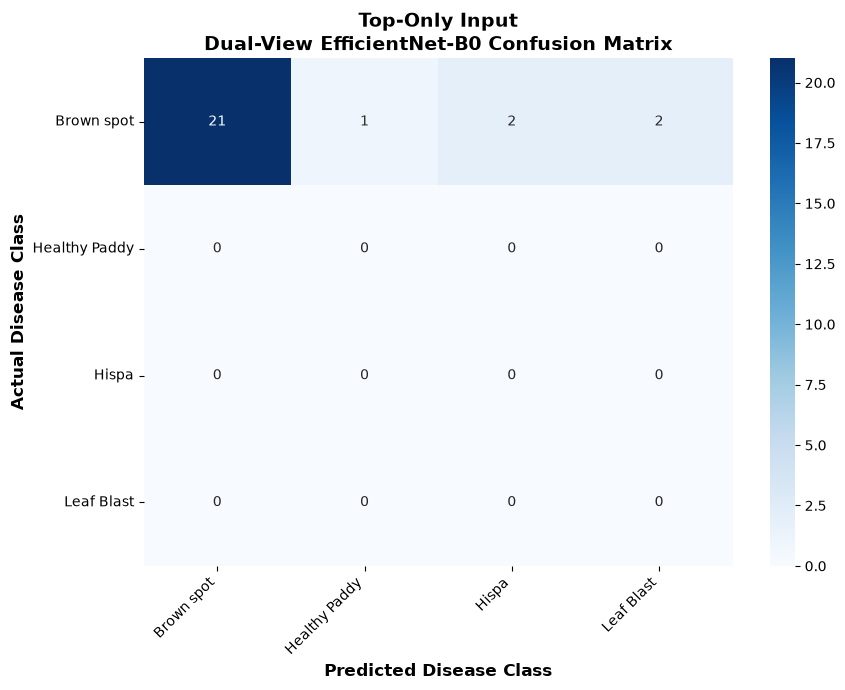


✓ Confusion matrix saved:
  D:\Testing\Brown Spot\Testing_Brown_Spot\top_only_confusion_matrix.png


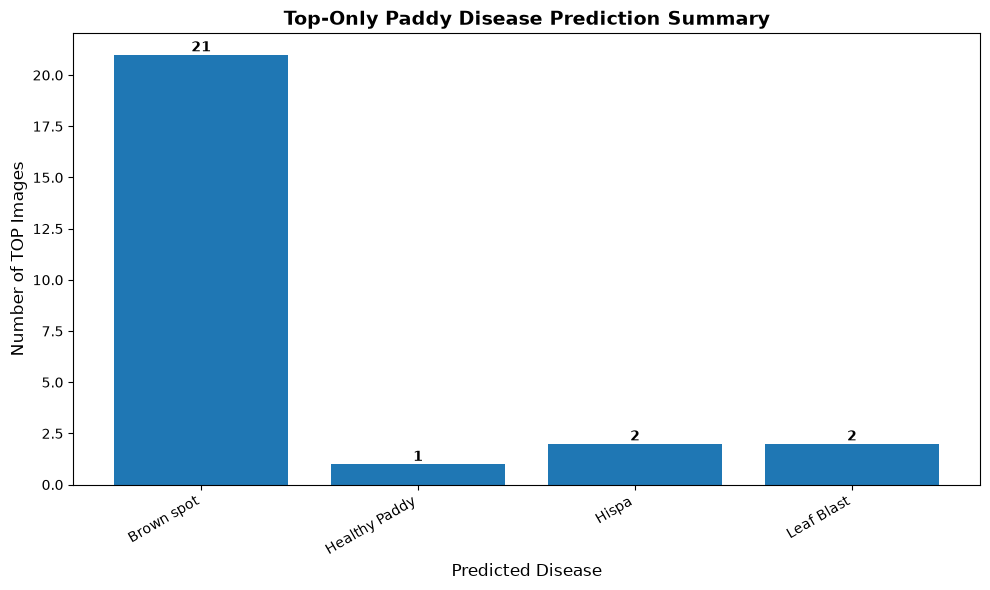


✓ Prediction summary chart saved:
  D:\Testing\Brown Spot\Testing_Brown_Spot\top_only_prediction_summary.png

                 TESTING COMPLETED
Testing folder       : D:\Testing\Brown Spot\Testing_Brown_Spot
Total images         : 28
TOP images tested    : 26
BOTTOM images ignored: 0
Predictions generated: 26
Results CSV          : D:\Testing\Brown Spot\Testing_Brown_Spot\top_only_test_predictions.csv
Summary chart        : D:\Testing\Brown Spot\Testing_Brown_Spot\top_only_prediction_summary.png

✓ ALL TOP-ONLY TESTING FINISHED SUCCESSFULLY


In [1]:
# ==============================================================================
# DUAL-VIEW EFFICIENTNET-B0
# TOP-ONLY TESTING
#
# IMPORTANT:
#
# The trained model still receives TWO inputs:
#
#       TOP IMAGE ──────────┐
#                           ├──> Dual-View EfficientNet-B0 ──> Prediction
#       SAME TOP IMAGE ─────┘
#
# The same TOP image is intentionally supplied to BOTH inputs.
#
# BOTTOM images are COMPLETELY IGNORED.
#
# Model:
# D:\Segregation\best_dual_efficientnet_b0.pth
# ==============================================================================


# ==============================================================================
# 1. IMPORTS
# ==============================================================================

import os
import re
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from tkinter import Tk, filedialog

import torch
import torch.nn as nn

from torchvision import transforms
from torchvision.models import efficientnet_b0

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
)


# ==============================================================================
# 2. CONFIGURATION
# ==============================================================================

BEST_MODEL_PATH = r"D:\Segregation\best_dual_efficientnet_b0.pth"

CLASSES = [
    "Brown spot",
    "Healthy Paddy",
    "Hispa",
    "Leaf Blast"
]

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
}

IMG_SIZE = 224

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


# ==============================================================================
# 3. START
# ==============================================================================

print("=" * 75)
print("        DUAL-VIEW EFFICIENTNET-B0")
print("             TOP-ONLY TESTING")
print("=" * 75)

print()
print("IMPORTANT:")
print("TOP image will be supplied to BOTH model inputs.")
print()
print("        TOP IMAGE ──────────┐")
print("                            ├──> MODEL")
print("        SAME TOP IMAGE ─────┘")
print()
print("BOTTOM images are completely ignored.")
print("=" * 75)


# ==============================================================================
# 4. DEVICE
# ==============================================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print()
print(f"✓ Device : {device}")

if torch.cuda.is_available():

    print(
        f"✓ GPU    : "
        f"{torch.cuda.get_device_name(0)}"
    )

    print(
        f"✓ VRAM   : "
        f"{torch.cuda.get_device_properties(0).total_memory / (1024 ** 3):.2f} GB"
    )

print("=" * 75)


# ==============================================================================
# 5. EVALUATION TRANSFORM
# ==============================================================================

eval_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


print()
print("✓ Evaluation transform ready")
print(
    f"  Image size : {IMG_SIZE} x {IMG_SIZE}"
)
print("  Channels   : RGB")
print("  Normalize  : ImageNet")

print("=" * 75)


# ==============================================================================
# 6. EXACT DUAL-VIEW MODEL ARCHITECTURE
# ==============================================================================

class DualViewEfficientNetB0(nn.Module):

    def __init__(
        self,
        num_classes=4,
        dropout_rate=0.3
    ):

        super().__init__()

        # ----------------------------------------------------------
        # EfficientNet-B0 backbone
        # ----------------------------------------------------------

        base_model = efficientnet_b0(
            weights=None
        )

        # ----------------------------------------------------------
        # Shared feature extractor
        # ----------------------------------------------------------

        self.features = base_model.features

        self.avgpool = base_model.avgpool

        backbone_features = (
            base_model.classifier[1].in_features
        )

        # EfficientNet-B0 = 1280
        assert backbone_features == 1280, (
            f"Unexpected EfficientNet-B0 feature size: "
            f"{backbone_features}"
        )

        # ----------------------------------------------------------
        # SAME classifier used during training
        #
        # 1280 TOP
        # +
        # 1280 BOTTOM
        # =
        # 2560
        #
        # 2560 -> 512 -> 4
        # ----------------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Dropout(
                p=dropout_rate,
                inplace=True
            ),

            nn.Linear(
                backbone_features * 2,
                512
            ),

            nn.BatchNorm1d(
                512
            ),

            nn.SiLU(
                inplace=True
            ),

            nn.Dropout(
                p=dropout_rate,
                inplace=True
            ),

            nn.Linear(
                512,
                num_classes
            )
        )


    # ==========================================================================
    # FEATURE EXTRACTION
    # ==========================================================================

    def extract_features(self, x):

        x = self.features(x)

        x = self.avgpool(x)

        x = torch.flatten(
            x,
            1
        )

        return x


    # ==========================================================================
    # FORWARD
    # ==========================================================================

    def forward(
        self,
        top,
        bottom
    ):

        top_features = self.extract_features(
            top
        )

        bottom_features = self.extract_features(
            bottom
        )

        combined = torch.cat(
            [
                top_features,
                bottom_features
            ],
            dim=1
        )

        output = self.classifier(
            combined
        )

        return output


# ==============================================================================
# 7. CREATE MODEL
# ==============================================================================

print()
print("=" * 75)
print("CREATING DUAL-VIEW EFFICIENTNET-B0")
print("=" * 75)

model = DualViewEfficientNetB0(
    num_classes=len(CLASSES),
    dropout_rate=0.3
)

print()
print("Number of classes :")
print(
    len(CLASSES)
)

print()
print("Classes:")

for i, cls in enumerate(CLASSES):

    print(
        f"  {i}: {cls}"
    )

print()
print(
    "Total parameters : "
    f"{sum(p.numel() for p in model.parameters()):,}"
)

print("=" * 75)


# ==============================================================================
# 8. CHECK MODEL FILE
# ==============================================================================

print()
print("=" * 75)
print("LOADING BEST MODEL")
print("=" * 75)

if not os.path.isfile(BEST_MODEL_PATH):

    raise FileNotFoundError(
        "\n❌ MODEL FILE NOT FOUND\n\n"
        f"Expected model:\n"
        f"{BEST_MODEL_PATH}\n"
    )


# ==============================================================================
# 9. LOAD CHECKPOINT
# ==============================================================================

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device
)

# ----------------------------------------------------------
# Handle normal state_dict
# ----------------------------------------------------------

if isinstance(
    checkpoint,
    dict
):

    # Sometimes checkpoint may contain state_dict
    if "state_dict" in checkpoint:

        state_dict = checkpoint[
            "state_dict"
        ]

    elif "model_state_dict" in checkpoint:

        state_dict = checkpoint[
            "model_state_dict"
        ]

    else:

        state_dict = checkpoint

else:

    state_dict = checkpoint


# ----------------------------------------------------------
# Remove possible "module." prefix
# ----------------------------------------------------------

clean_state_dict = {}

for key, value in state_dict.items():

    if key.startswith("module."):

        clean_key = key[
            len("module.") :
        ]

    else:

        clean_key = key

    clean_state_dict[
        clean_key
    ] = value


# ==============================================================================
# 10. LOAD WEIGHTS
# ==============================================================================

try:

    model.load_state_dict(
        clean_state_dict,
        strict=True
    )

except RuntimeError as e:

    print()
    print("=" * 75)
    print("❌ MODEL WEIGHT LOADING ERROR")
    print("=" * 75)

    print(e)

    print()
    print(
        "This means the architecture in this testing code "
        "does not exactly match the architecture used during training."
    )

    raise


# ==============================================================================
# 11. MOVE MODEL TO DEVICE
# ==============================================================================

model = model.to(
    device
)

model.eval()


print()
print(
    "✓ Best model loaded successfully"
)

print(
    f"✓ Model path : {BEST_MODEL_PATH}"
)

print(
    f"✓ Device     : {device}"
)

if torch.cuda.is_available():

    print(
        f"✓ GPU        : "
        f"{torch.cuda.get_device_name(0)}"
    )

print("=" * 75)


# ==============================================================================
# 12. SELECT TESTING FOLDER
# ==============================================================================

print()
print("=" * 75)
print("              TOP-ONLY TESTING DATASET")
print("=" * 75)

print(
    """
Select your TESTING DATASET folder.

Example:

D:\\Testing\\Leaf Blast

or

D:\\Testing

The code will automatically find TOP images.

Examples of TOP images:

000002_t1.JPG
000004_t2.JPG
000206_t698.JPG
000208_t700.JPG

BOTTOM images such as:

000001_b1.JPG
000003_b2.JPG
000205_b698.JPG

will be COMPLETELY IGNORED.
"""
)


# ==============================================================================
# 13. WINDOWS FOLDER DIALOG
# ==============================================================================

root = Tk()

root.withdraw()

root.attributes(
    "-topmost",
    True
)

TEST_DIR = filedialog.askdirectory(
    title="Select TOP-ONLY Testing Dataset Folder"
)

root.destroy()


# ==============================================================================
# 14. CHECK FOLDER
# ==============================================================================

if not TEST_DIR:

    print()
    print("❌ No folder selected.")
    print("Testing cancelled.")

else:

    TEST_DIR = str(
        Path(TEST_DIR)
    )

    test_path = Path(
        TEST_DIR
    )

    print()
    print(
        "✓ Testing folder selected:"
    )

    print(
        f"  {TEST_DIR}"
    )


    # ==========================================================================
    # 15. FIND ALL IMAGES
    # ==========================================================================

    print()
    print("=" * 75)
    print("TEST DATASET DISCOVERY")
    print("=" * 75)

    all_test_files = [

        f

        for f in test_path.rglob("*")

        if (
            f.is_file()
            and
            f.suffix.lower()
            in IMAGE_EXTENSIONS
        )
    ]


    print(
        f"Total images discovered : "
        f"{len(all_test_files)}"
    )


    # ==========================================================================
    # 16. IDENTIFY TOP IMAGES ONLY
    # ==========================================================================

    def is_top_image(
        file_path
    ):

        name = file_path.stem.lower()

        # ----------------------------------------------------------
        # Accepted:
        #
        # 000001_t1
        # 000002_t2
        # 000206_t698
        #
        # ----------------------------------------------------------

        patterns = [

            r"[_-]t\d+$",

            r"^t\d+$"

        ]

        for pattern in patterns:

            if re.search(
                pattern,
                name
            ):

                return True

        return False


    # ==========================================================================
    # 17. FIND TOP IMAGES
    # ==========================================================================

    top_files = []

    ignored_bottom = []

    unknown_images = []


    for file_path in all_test_files:

        name = file_path.stem.lower()


        # ----------------------------------------------------------
        # TOP
        # ----------------------------------------------------------

        if is_top_image(
            file_path
        ):

            top_files.append(
                file_path
            )

            continue


        # ----------------------------------------------------------
        # BOTTOM
        # ----------------------------------------------------------

        if re.search(
            r"[_-]b\d+$",
            name
        ):

            ignored_bottom.append(
                file_path
            )

            continue


        # ----------------------------------------------------------
        # Unknown image naming
        # ----------------------------------------------------------

        unknown_images.append(
            file_path
        )


    # ==========================================================================
    # 18. SORT TOP IMAGES
    # ==========================================================================

    top_files = sorted(
        top_files,
        key=lambda x: (
            x.parent.as_posix().lower(),
            x.name.lower()
        )
    )


    print()
    print(
        f"TOP images found       : "
        f"{len(top_files)}"
    )

    print(
        f"BOTTOM images ignored  : "
        f"{len(ignored_bottom)}"
    )

    print(
        f"Unknown images ignored : "
        f"{len(unknown_images)}"
    )


    # ==========================================================================
    # 19. STOP IF NO TOP IMAGES
    # ==========================================================================

    if len(top_files) == 0:

        print()
        print(
            "❌ No TOP images were found."
        )

        print()
        print(
            "Expected filenames such as:"
        )

        print(
            "  000002_t1.JPG"
        )

        print(
            "  000004_t2.JPG"
        )

        print(
            "  000206_t698.JPG"
        )


    else:

        # ======================================================================
        # 20. DISPLAY FIRST 10 TOP IMAGES
        # ======================================================================

        print()
        print("=" * 75)
        print("TOP IMAGE VERIFICATION")
        print("=" * 75)

        for i, file_path in enumerate(
            top_files[:10],
            start=1
        ):

            print(
                f"{i:02d}. "
                f"{file_path.name}"
            )

        print("=" * 75)


        # ======================================================================
        # 21. CLASS DETECTION
        # ======================================================================

        def normalize_class_name(
            name
        ):

            return (
                name
                .lower()
                .replace(
                    " ",
                    ""
                )
                .replace(
                    "_",
                    ""
                )
                .replace(
                    "-",
                    ""
                )
            )


        normalized_classes = {

            normalize_class_name(cls): cls

            for cls in CLASSES
        }


        def get_true_class(
            file_path
        ):

            # ------------------------------------------------------
            # Search parent folders
            # ------------------------------------------------------

            for parent in file_path.parents:

                normalized = (
                    normalize_class_name(
                        parent.name
                    )
                )

                if normalized in normalized_classes:

                    return normalized_classes[
                        normalized
                    ]


            return None


        # ======================================================================
        # 22. TESTING
        # ======================================================================

        print()
        print("=" * 75)
        print("RUNNING TOP-ONLY DUAL-VIEW TESTING")
        print("=" * 75)

        print()
        print(
            "Each TOP image is passed twice:"
        )

        print(
            "  Model Input 1 = TOP"
        )

        print(
            "  Model Input 2 = SAME TOP"
        )

        print()
        print(
            "BOTTOM images are NOT used."
        )

        print("=" * 75)


        predictions = []

        prediction_counts = Counter()


        # ======================================================================
        # 23. INFERENCE
        # ======================================================================

        with torch.inference_mode():

            for count, top_file in enumerate(
                top_files,
                start=1
            ):

                try:

                    # ----------------------------------------------------------
                    # Load TOP image
                    # ----------------------------------------------------------

                    img_top = Image.open(
                        top_file
                    ).convert(
                        "RGB"
                    )


                    # ----------------------------------------------------------
                    # Transform TOP image
                    # ----------------------------------------------------------

                    tensor_top = (
                        eval_transform(
                            img_top
                        )
                        .unsqueeze(0)
                        .to(
                            device,
                            non_blocking=True
                        )
                    )


                    # ----------------------------------------------------------
                    # CRITICAL:
                    #
                    # SAME TOP IMAGE is supplied to BOTH inputs.
                    #
                    # NO BOTTOM IMAGE IS USED.
                    # ----------------------------------------------------------

                    tensor_bottom = tensor_top


                    # ----------------------------------------------------------
                    # MODEL
                    # ----------------------------------------------------------

                    outputs = model(
                        tensor_top,
                        tensor_bottom
                    )


                    # ----------------------------------------------------------
                    # Probability
                    # ----------------------------------------------------------

                    probs = torch.softmax(
                        outputs,
                        dim=1
                    )[0]


                    probs_np = (
                        probs
                        .detach()
                        .cpu()
                        .numpy()
                    )


                    # ----------------------------------------------------------
                    # Highest probability class
                    # ----------------------------------------------------------

                    pred_idx = int(
                        np.argmax(
                            probs_np
                        )
                    )


                    confidence = float(
                        probs_np[
                            pred_idx
                        ]
                    )


                    pred_class = CLASSES[
                        pred_idx
                    ]


                    # ----------------------------------------------------------
                    # True class
                    # ----------------------------------------------------------

                    true_class = get_true_class(
                        top_file
                    )


                    # ----------------------------------------------------------
                    # Pair / leaf number
                    # ----------------------------------------------------------

                    name = top_file.stem.lower()

                    pair_match = re.search(
                        r"[_-]t(\d+)$",
                        name
                    )


                    if pair_match:

                        leaf_id = int(
                            pair_match.group(1)
                        )

                    else:

                        leaf_id = count


                    # ----------------------------------------------------------
                    # Record
                    # ----------------------------------------------------------

                    record = {

                        "Leaf_ID":
                            leaf_id,

                        "Top_Image":
                            top_file.name,

                        "Predicted_Class":
                            pred_class,

                        "Confidence":
                            confidence,

                        "True_Class":
                            true_class
                    }


                    # ----------------------------------------------------------
                    # Probability for every class
                    # ----------------------------------------------------------

                    for c_idx, c_name in enumerate(
                        CLASSES
                    ):

                        record[
                            f"Prob_{c_name}"
                        ] = float(
                            probs_np[
                                c_idx
                            ]
                        )


                    predictions.append(
                        record
                    )


                    # ----------------------------------------------------------
                    # Prediction counter
                    # ----------------------------------------------------------

                    prediction_counts[
                        pred_class
                    ] += 1


                    # ----------------------------------------------------------
                    # Print result
                    # ----------------------------------------------------------

                    print(

                        f"{count:04d}/"
                        f"{len(top_files):04d} | "

                        f"{top_file.name:<35} | "

                        f"→ {pred_class:<18} | "

                        f"{confidence * 100:6.2f}%"

                    )


                except Exception as e:

                    print()
                    print(
                        f"❌ Error processing:"
                    )

                    print(
                        f"   {top_file}"
                    )

                    print(
                        f"   {type(e).__name__}: {e}"
                    )

                    print()


        # ======================================================================
        # 24. DATAFRAME
        # ======================================================================

        df_test_results = pd.DataFrame(
            predictions
        )


        # ======================================================================
        # 25. SAVE CSV
        # ======================================================================

        results_csv = (
            test_path /
            "top_only_test_predictions.csv"
        )


        df_test_results.to_csv(
            results_csv,
            index=False
        )


        print()
        print("=" * 75)
        print("PREDICTION RESULTS SAVED")
        print("=" * 75)

        print(
            f"✓ CSV:"
        )

        print(
            f"  {results_csv}"
        )


        # ======================================================================
        # 26. PREDICTION COUNT
        # ======================================================================

        print()
        print("=" * 75)
        print("PREDICTED CLASS COUNTS")
        print("=" * 75)


        for cls in CLASSES:

            print(
                f"{cls:<22}: "
                f"{prediction_counts.get(cls, 0)}"
            )


        print()
        print(
            f"Prediction Count       : "
            f"{len(predictions)}/{len(top_files)}"
        )

        print("=" * 75)


        # ======================================================================
        # 27. EVALUATION
        # ======================================================================

        labeled_test = df_test_results[
            df_test_results[
                "True_Class"
            ].notnull()
        ]


        if len(labeled_test) > 0:

            y_true = labeled_test[
                "True_Class"
            ].tolist()

            y_pred = labeled_test[
                "Predicted_Class"
            ].tolist()


            # ------------------------------------------------------------------
            # Accuracy
            # ------------------------------------------------------------------

            acc = accuracy_score(
                y_true,
                y_pred
            )


            # ------------------------------------------------------------------
            # Macro
            # ------------------------------------------------------------------

            (
                macro_p,
                macro_r,
                macro_f1,
                _
            ) = precision_recall_fscore_support(

                y_true,
                y_pred,

                labels=CLASSES,

                average="macro",

                zero_division=0
            )


            # ------------------------------------------------------------------
            # Weighted
            # ------------------------------------------------------------------

            (
                weighted_p,
                weighted_r,
                weighted_f1,
                _
            ) = precision_recall_fscore_support(

                y_true,
                y_pred,

                labels=CLASSES,

                average="weighted",

                zero_division=0
            )


            # ==================================================================
            # 28. FINAL METRICS
            # ==================================================================

            print()
            print("=" * 75)
            print("FINAL TEST EVALUATION METRICS")
            print("=" * 75)

            print(
                f"Total Test TOP Images : "
                f"{len(labeled_test)}"
            )

            print(
                f"Overall Accuracy      : "
                f"{acc * 100:.2f}%"
            )

            print(
                f"Macro Precision       : "
                f"{macro_p * 100:.2f}%"
            )

            print(
                f"Macro Recall          : "
                f"{macro_r * 100:.2f}%"
            )

            print(
                f"Macro F1-Score        : "
                f"{macro_f1 * 100:.2f}%"
            )

            print(
                f"Weighted F1-Score     : "
                f"{weighted_f1 * 100:.2f}%"
            )

            print("=" * 75)


            # ==================================================================
            # 29. CLASSIFICATION REPORT
            # ==================================================================

            print()
            print("CLASSIFICATION REPORT")
            print("=" * 75)

            print(
                classification_report(

                    y_true,
                    y_pred,

                    labels=CLASSES,

                    target_names=CLASSES,

                    digits=4,

                    zero_division=0
                )
            )


            # ==================================================================
            # 30. CONFUSION MATRIX
            # ==================================================================

            cm = confusion_matrix(
                y_true,
                y_pred,
                labels=CLASSES
            )


            plt.figure(
                figsize=(9, 7)
            )


            sns.heatmap(

                cm,

                annot=True,

                fmt="d",

                cmap="Blues",

                xticklabels=CLASSES,

                yticklabels=CLASSES
            )


            plt.xlabel(
                "Predicted Disease Class",
                fontsize=12,
                fontweight="bold"
            )


            plt.ylabel(
                "Actual Disease Class",
                fontsize=12,
                fontweight="bold"
            )


            plt.title(
                "Top-Only Input\n"
                "Dual-View EfficientNet-B0 "
                "Confusion Matrix",

                fontsize=14,

                fontweight="bold"
            )


            plt.xticks(
                rotation=45,
                ha="right"
            )

            plt.yticks(
                rotation=0
            )


            plt.tight_layout()


            confusion_path = (
                test_path /
                "top_only_confusion_matrix.png"
            )


            plt.savefig(
                confusion_path,
                dpi=300,
                bbox_inches="tight"
            )


            plt.show()


            print()
            print(
                "✓ Confusion matrix saved:"
            )

            print(
                f"  {confusion_path}"
            )


        else:

            # ==================================================================
            # UNLABELED DATA
            # ==================================================================

            print()
            print("=" * 75)
            print("UNLABELED TEST DATA")
            print("=" * 75)

            print(
                "No recognized disease-class folder was found."
            )

            print()
            print(
                "Predictions were generated successfully."
            )

            print()
            print(
                "Accuracy cannot be calculated because "
                "true labels are unavailable."
            )


        # ======================================================================
        # 31. PREDICTION SUMMARY CHART
        # ======================================================================

        plt.figure(
            figsize=(10, 6)
        )


        counts = [

            int(
                prediction_counts.get(
                    cls,
                    0
                )
            )

            for cls in CLASSES
        ]


        bars = plt.bar(
            CLASSES,
            counts
        )


        plt.xlabel(
            "Predicted Disease",
            fontsize=12
        )


        plt.ylabel(
            "Number of TOP Images",
            fontsize=12
        )


        plt.title(
            "Top-Only Paddy Disease "
            "Prediction Summary",

            fontsize=14,

            fontweight="bold"
        )


        plt.xticks(
            rotation=30,
            ha="right"
        )


        for bar, count in zip(
            bars,
            counts
        ):

            plt.text(

                bar.get_x()
                + bar.get_width() / 2,

                bar.get_height(),

                str(count),

                ha="center",

                va="bottom",

                fontweight="bold"
            )


        plt.tight_layout()


        summary_chart_path = (
            test_path /
            "top_only_prediction_summary.png"
        )


        plt.savefig(
            summary_chart_path,
            dpi=300,
            bbox_inches="tight"
        )


        plt.show()


        print()
        print(
            "✓ Prediction summary chart saved:"
        )

        print(
            f"  {summary_chart_path}"
        )


        # ======================================================================
        # 32. FINAL SUMMARY
        # ======================================================================

        print()
        print("=" * 75)
        print("                 TESTING COMPLETED")
        print("=" * 75)

        print(
            f"Testing folder       : "
            f"{TEST_DIR}"
        )

        print(
            f"Total images         : "
            f"{len(all_test_files)}"
        )

        print(
            f"TOP images tested    : "
            f"{len(top_files)}"
        )

        print(
            f"BOTTOM images ignored: "
            f"{len(ignored_bottom)}"
        )

        print(
            f"Predictions generated: "
            f"{len(df_test_results)}"
        )

        print(
            f"Results CSV          : "
            f"{results_csv}"
        )

        print(
            f"Summary chart        : "
            f"{summary_chart_path}"
        )

        print("=" * 75)

        print()
        print(
            "✓ ALL TOP-ONLY TESTING FINISHED SUCCESSFULLY"
        )

In [62]:
import shutil
import torch

FINAL_MODEL_PATH = "/content/Dual_EfficientNet_B0_Paddy_Disease.pth"
torch.save(model.state_dict(), FINAL_MODEL_PATH)
print(f"✓ Saved final model weights: {FINAL_MODEL_PATH}")

# List of all artifacts generated
artifacts = [
    FINAL_MODEL_PATH,
    "/content/class_to_idx.json",
    "/content/accuracy_curve.png",
    "/content/loss_curve.png",
    "/content/test_confusion_matrix.png",
    "/content/test_predictions.csv"
]

print("\n" + "=" * 55)
print("PROJECT ARTIFACTS READY FOR DOWNLOAD")
print("=" * 55)
for art in artifacts:
    if os.path.exists(art):
        size_kb = os.path.getsize(art) / 1024
        print(f"  ✓ {os.path.basename(art):<35} ({size_kb:.1f} KB)")
    else:
        print(f"  - {os.path.basename(art):<35} (Not generated)")
print("=" * 55)

# Trigger Google Colab browser download
try:
    from google.colab import files
    print("Starting browser download of key artifacts...")
    for art in artifacts:
        if os.path.exists(art):
            files.download(art)
    print("✓ All files sent to browser download manager!")
except Exception as e:
    print("Note on browser download:", e)
    print("All artifacts remain permanently saved in '/content/' for manual download.")

✓ Saved final model weights: /content/Dual_EfficientNet_B0_Paddy_Disease.pth

PROJECT ARTIFACTS READY FOR DOWNLOAD
  ✓ Dual_EfficientNet_B0_Paddy_Disease.pth (21096.4 KB)
  ✓ class_to_idx.json                   (0.1 KB)
  ✓ accuracy_curve.png                  (281.1 KB)
  ✓ loss_curve.png                      (281.1 KB)
  ✓ test_confusion_matrix.png           (138.4 KB)
  ✓ test_predictions.csv                (24.9 KB)
Note on browser download: No module named 'google.colab'
All artifacts remain permanently saved in '/content/' for manual download.
